# 📚 Sistema de Recomendação de Livros

**Versão 2** do projeto, no roteiro CRISP-DM e no padrão de construção do portfólio. O notebook original (v1) continua no repositório para mostrar a evolução.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Uma livraria online tem centenas de milhares de títulos, mas cada cliente vê só alguns na tela. Mostrar a todos os mesmos best-sellers é fácil, porém deixa de fora o que **cada leitor** gostaria de ler. Um sistema de recomendação usa o histórico de leitura de milhares de pessoas para sugerir, a cada cliente, os livros que leitores parecidos com ele leram e gostaram.

**Fonte dos dados:** [Book-Crossing Dataset](https://www.kaggle.com/datasets/arashnic/book-recommendation-dataset) (Cai-Nicolas Ziegler, 2004). A base reúne as interações de usuários da comunidade *Book-Crossing* com livros identificados pelo ISBN; as capas apontam para imagens da Amazon.

## 🎯 Objetivo

Recomendar a cada leitor **10 livros** que ele ainda não leu e de que provavelmente vai gostar, e **medir** quantas vezes a lista acerta, comparando com o que uma livraria faria sem modelo (mostrar os mais populares).

## 🧩 Formato da solução

- **Granularidade:** um usuário (ou um leitor novo que informa alguns livros de que gostou).
- **Tipo de problema:** recomendação top-N por **filtragem colaborativa** (aprende quais livros são lidos juntos, sem usar o conteúdo dos livros).
- **O que conta como acerto:** um livro que o usuário avaliou com **nota 7 ou mais** ("gostou"), escondido do modelo, aparecer entre os 10 recomendados.
- **Entrega:** modelo salvo, ficha do modelo e um app Streamlit em que o leitor escolhe livros de que gostou e recebe 10 recomendações com capa e o motivo de cada uma.

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Contexto, objetivo e o que conta como acerto |
| **02. Preparação dos dados** | Leitura, significado real das colunas, correção de linhas deslocadas, obras (título + autor), nulos, outliers, 8 hipóteses com teste estatístico e catálogo |
| **03. Modelagem** | Separação 60/20/20 por usuário, 6 recomendadores, separações repetidas (média ± desvio), ajuste fino, tamanho da lista e teste anti-vazamento |
| **04. Avaliação** | Acerto no teste por perfil de leitor e popularidade do livro, exemplos e explicação das recomendações |
| **05. Implantação** | Modelo e ficha salvos, simulação com leitores novos e app Streamlit |

📌 **Nota: o que muda em relação à versão original (v1)**

| Problema na v1 | O que a v2 faz |
|---|---|
| O README diz que a base tem "3.150 clientes da Amazon" | A base é a **Book-Crossing** (2004): 278.858 usuários cadastrados, 271.360 ISBNs e 1.149.780 interações |
| A nota 0 foi lida como nota ruim ("o site da Amazon está muito ruim para vender livros") e descartada | A nota 0 é uma **interação sem nota**: o usuário registrou o livro, mas não o avaliou. A v2 testa se usar essas interações melhora as recomendações |
| O livro era identificado só pelo título: livros diferentes com o mesmo título viravam um só, e edições repetidas tinham a nota tirada pela média sem aviso | **Obra = título + autor normalizados** |
| Distância euclidiana sobre notas, com zero onde o usuário não leu: o 5º livro "parecido" com Harry Potter 2 era *Don't Stand Too Close to a Naked Man* | Similaridade de cosseno, fatoração (SVD) e EASE, comparados com o euclidiano da v1 |
| Nenhuma medida de acerto: o "altamente relevante" do README não foi medido | Separação 60/20/20 por usuário, **acerto@10**, precisão, recall, NDCG e cobertura, comparados com os mais populares e com o sorteio |
| O próprio livro escolhido aparecia como recomendação, ocupando 1 das 5 vagas | Os livros que o leitor já tem nunca são recomendados |
| A simulação mostrava *Sorcerer's Stone* como livro escolhido, mas o livro usado era o 213 (*Chamber of Secrets*): a célula usava uma variável que não existia no notebook | Simulação com leitores novos, a partir do modelo salvo |
| Títulos coloridos com HTML, sem testes, sem app | Notas no padrão do portfólio, `src/` com testes, app Streamlit |

# FASE 02: PREPARAÇÃO DOS DADOS

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import pickle
import warnings

import numpy              as np
import pandas             as pd
import seaborn            as sns
import matplotlib.pyplot  as plt
from scipy                import stats
from sklearn.model_selection import ParameterGrid

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

sys.path.append('..')
from src.config import (PASTA_MODELO, PASTA_REPORTS, PASTA_IMAGENS, SEMENTE, SEMENTES_VALIDACAO, NOTA_IMPLICITA,
                        NOTA_GOSTOU, MIN_NOTAS_CATALOGO, MIN_GOSTOU_AVALIACAO, TAMANHO_LISTA,
                        NOTA_MINIMA_RECOMENDAR)
from src.dados import (ler_bases, limpar_livros, criar_obras, montar_interacoes, montar_catalogo,
                       filtrar_sinal, populares_bem_avaliados, extrair_pais)
from src.estatistica import regra_iqr, teste_mann_whitney, teste_spearman, teste_qui_quadrado, odds_ratio
from src.recomendacao import (matriz_usuario_item, separar_por_usuario, montar_matrizes, Aleatorio, Popularidade,
                              VizinhosItens, FatoracaoSVD, EASE, livros_mal_avaliados, avaliar_recomendador,
                              comparar_lista, explicar_recomendacao, recomendar_para_leitor,
                              acerto_por_livros_informados)
from src.avaliacao import salvar_ficha_modelo

PASTA_REPORTS.mkdir(exist_ok=True)
PASTA_MODELO.mkdir(exist_ok=True)


def salvar_figura(nome):
    """Salva a figura atual em Imagens/ (usada no README)."""
    plt.savefig(PASTA_IMAGENS / f'{nome}.png', bbox_inches='tight', dpi=100)

#### Funções auxiliares

As funções ficam na pasta `src/` (com docstrings e testes em `tests/`), para que o notebook mostre só a análise.

| Módulo | Funções | Para quê |
|---|---|---|
| `src/config.py` | `NOTA_GOSTOU`, `MIN_NOTAS_CATALOGO`, `TAMANHO_LISTA`, `SEMENTES_VALIDACAO` | Nota que conta como "gostou", corte do catálogo, tamanho da lista e sementes |
| `src/dados.py` | `ler_bases`, `limpar_livros`, `criar_obras` | Leitura com nomes em português, conserto das linhas deslocadas e das entidades HTML, obra = título + autor |
| `src/dados.py` | `montar_interacoes`, `montar_catalogo`, `filtrar_sinal`, `populares_bem_avaliados`, `extrair_pais` | Interações usuário × obra, catálogo, sinal usado no treino e lista para quem não tem histórico |
| `src/estatistica.py` | `regra_iqr`, `teste_mann_whitney`, `teste_spearman`, `teste_qui_quadrado`, `odds_ratio` | Outliers e testes das hipóteses, sempre com tamanho do efeito |
| `src/recomendacao.py` | `matriz_usuario_item`, `separar_por_usuario`, `montar_matrizes` | Matriz esparsa e separação 60/20/20 por usuário |
| `src/recomendacao.py` | `Aleatorio`, `Popularidade`, `VizinhosItens`, `FatoracaoSVD`, `EASE` | Os 6 recomendadores (o euclidiano da v1 é `VizinhosItens(metrica='euclidiana')`) |
| `src/recomendacao.py` | `livros_mal_avaliados` | Filtro de qualidade: livros com nota média abaixo de 5 nunca são recomendados |
| `src/recomendacao.py` | `avaliar_recomendador`, `comparar_lista`, `explicar_recomendacao`, `recomendar_para_leitor` | Acerto@10, precisão, recall, NDCG e cobertura; exemplos; o motivo de cada recomendação |
| `src/recomendacao.py` | `acerto_por_livros_informados` | Acerto esperado quando o leitor informa só 1, 2, 3, 5 ou 10 livros (o que o app mostra) |
| `src/avaliacao.py` | `salvar_ficha_modelo` | Ficha do modelo em JSON |

### 1.2. Salvar a base em CSV

🚫 **Não se aplica.** As três tabelas já estão em CSV na pasta `Datasets/` (`Books.csv`, `Ratings.csv` e `Users.csv`).

## 2 - LIMPEZA DOS DADOS

### 2.1. Leitura dos dados

In [2]:
livros_brutos, avaliacoes, usuarios = ler_bases()
print(f'Livros: {livros_brutos.shape} | Avaliações: {avaliacoes.shape} | Usuários: {usuarios.shape}')
display(livros_brutos.head(3))
display(avaliacoes.head(3))
usuarios.head(3)

Livros: (271360, 8) | Avaliações: (1149780, 3) | Usuários: (278858, 3)


,isbn,titulo,autor,ano,editora,capa_p,capa_m,capa_g
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg


,id_usuario,isbn,nota
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0


,id_usuario,local,idade
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN


### 2.2. Colunas

**Dicionário de dados** (com o significado documentado da base Book-Crossing):

| Tabela | Coluna original | Coluna | Significado |
|---|---|---|---|
| Livros | `ISBN` | `isbn` | Código do livro (cada edição tem o seu) |
| Livros | `Book-Title`, `Book-Author` | `titulo`, `autor` | Título e autor |
| Livros | `Year-Of-Publication`, `Publisher` | `ano`, `editora` | Ano de publicação e editora |
| Livros | `Image-URL-S/M/L` | `capa_p`, `capa_m`, `capa_g` | Capa (pequena, média e grande) na Amazon |
| Avaliações | `User-ID` | `id_usuario` | Usuário (anônimo) |
| Avaliações | `Book-Rating` | `nota` | **0 = interação sem nota** (o usuário registrou o livro, mas não avaliou); **1 a 10 = nota explícita** |
| Usuários | `Location`, `Age` | `local`, `idade` | "cidade, estado, país" e idade |

In [3]:
deslocadas = livros_brutos['titulo'].str.contains('";', regex=False, na=False)
print('Linhas com título e autor juntos:', deslocadas.sum())
display(livros_brutos.loc[deslocadas, ['isbn', 'titulo', 'autor', 'ano', 'editora']])

livros = criar_obras(limpar_livros(livros_brutos))
livros.loc[deslocadas, ['isbn', 'titulo', 'autor', 'ano', 'editora']]

Linhas com título e autor juntos: 3


,isbn,titulo,autor,ano,editora
209538,078946697X,"DK Readers: Creating the X-Men, How It All Began (Level 4: Profici...",2000,DK Publishing Inc,http://images.amazon.com/images/P/078946697X.01.THUMBZZZ.jpg
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers\"";Jean-Marie Gustave Le ClÃ?...",2003,Gallimard,http://images.amazon.com/images/P/2070426769.01.THUMBZZZ.jpg
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Books Come to Life (Leve...",2000,DK Publishing Inc,http://images.amazon.com/images/P/0789466953.01.THUMBZZZ.jpg


,isbn,titulo,autor,ano,editora
209538,078946697X,"DK Readers: Creating the X-Men, How It All Began (Level 4: Profici...",Michael Teitelbaum,2000,DK Publishing Inc
220731,2070426769,"Peuple du ciel, suivi de 'Les Bergers",Jean-Marie Gustave Le ClÃ?Â©zio,2003,Gallimard
221678,0789466953,"DK Readers: Creating the X-Men, How Comic Books Come to Life (Leve...",James Buckley,2000,DK Publishing Inc


In [4]:
print(f"ISBNs: {livros['isbn'].nunique():,} | títulos: {livros['titulo'].nunique():,} | "
      f"obras (título + autor): {livros['id_obra'].nunique():,}")
autores_por_titulo = livros.groupby('titulo')['autor'].nunique()
print(f'Títulos com mais de um autor: {(autores_por_titulo > 1).sum():,}')
autores_por_titulo.sort_values(ascending=False).head(5).rename('autores diferentes')

ISBNs: 271,360 | títulos: 242,135 | obras (título + autor): 245,577


Títulos com mais de um autor: 6,748


titulo
Selected Poems    25
The Gift          12
Dinosaurs         12
Masquerade        11
The Secret        11
Name: autores diferentes, dtype: int64

📌 **Nota: colunas, linhas deslocadas e obras**
- 🔎 **3 linhas** do cadastro vieram com o título e o autor na mesma coluna e as colunas seguintes deslocadas (o ano estava no lugar do autor). `limpar_livros` conserta as três e também troca as entidades HTML (`&amp;` → `&`).
- 🔎 Há **242.135** títulos para **271.360** ISBNs, porque cada edição tem um ISBN próprio. Mas **6.748** títulos têm mais de um autor: *Selected Poems* aparece com **25** autores diferentes.
- ⚠️ A versão original identificava o livro só pelo título, juntando livros diferentes com o mesmo nome. ✅ Na v2, a **obra** é título + autor normalizados (**245.577** obras): as edições de um livro se juntam e livros diferentes ficam separados.

### 2.3. Dimensões dos dados

In [5]:
explicita = avaliacoes['nota'] > NOTA_IMPLICITA
fora = ~avaliacoes['isbn'].isin(livros['isbn'])
dimensoes = pd.DataFrame({'interações': [len(avaliacoes), explicita.sum()],
                          'ISBN fora do catálogo': [fora.sum(), (fora & explicita).sum()]},
                         index=['todas', 'com nota (1 a 10)'])
dimensoes['% fora'] = (dimensoes['ISBN fora do catálogo'] / dimensoes['interações']).round(3)
print(f"Usuários com interações: {avaliacoes['id_usuario'].nunique():,} de {len(usuarios):,} cadastrados")
print('Duplicatas usuário × ISBN:', avaliacoes.duplicated(['id_usuario', 'isbn']).sum())
dimensoes

Usuários com interações: 105,283 de 278,858 cadastrados


Duplicatas usuário × ISBN: 0


,interações,ISBN fora do catálogo,% fora
todas,1149780,118644,0.103
com nota (1 a 10),433671,49829,0.115


📌 **Nota: dimensões**
- 🔎 Só **105.283** dos **278.858** usuários cadastrados têm alguma interação; os demais não entram em nada.
- 🔎 **10,3%** das interações (e **11,5%** das notas explícitas) são de ISBNs que não estão no cadastro de livros: não há título nem autor para eles, então ficam de fora.
- 🔎 Nenhuma duplicata usuário × ISBN.

### 2.4. Valores nulos

In [6]:
nulos = pd.concat({'livros': livros.drop(columns='id_obra').isna().sum(), 'usuários': usuarios.isna().sum()}).rename('nulos').to_frame()
nulos['% nulos'] = [n / (len(livros) if tabela == 'livros' else len(usuarios)) for (tabela, _), n in nulos['nulos'].items()]
nulos.query('nulos > 0').round(3)

nulos  % nulos
livros   autor         2    0.000
         editora       2    0.000
usuários idade    110762    0.397

📌 **Nota: nulos**
- 🔎 **39,7%** das idades estão vazias; o autor e a editora faltam em só 2 livros.
- ✅ **Decisão:** nada a preencher. O modelo usa só quem leu o quê; a idade aparece apenas na H5, com as idades válidas.

### 2.5. Estatística descritiva

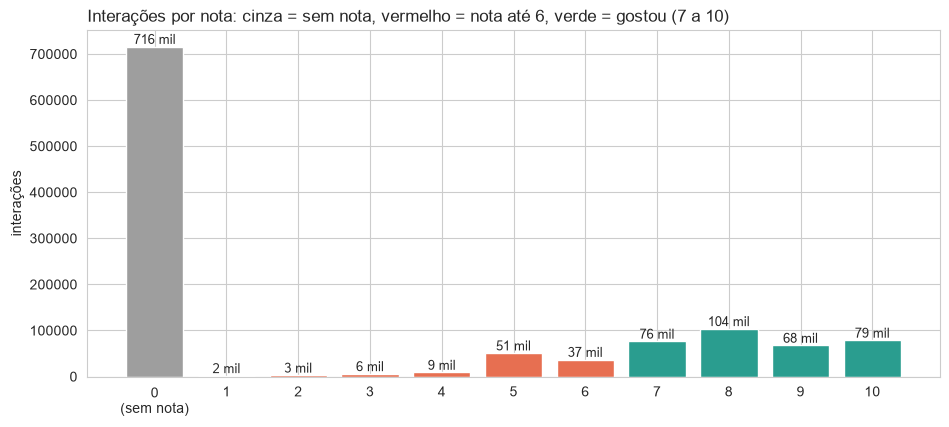

Interações sem nota (0): 62.3%


,count,mean,std,min,25%,50%,75%,max
notas de 1 a 10,433671.0,7.6,1.84,1.0,7.0,8.0,9.0,10.0


Ano 0: 4,618 livros | depois de 2004 (ano da coleta): 72 | máximo: 2050


,count,mean,std,min,25%,50%,75%,max
idade,168096.0,34.8,14.4,0.0,24.0,32.0,44.0,244.0


In [7]:
contagem = avaliacoes['nota'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 4.5))
cores = ['#9e9e9e'] + ['#e76f51'] * 6 + ['#2a9d8f'] * 4
ax.bar(contagem.index, contagem.values, color=cores)
for nota, valor in contagem.items():
    ax.annotate(f'{valor / 1000:.0f} mil', (nota, valor), ha='center', va='bottom', fontsize=9)
ax.set_xticks(range(11), ['0\n(sem nota)'] + [str(n) for n in range(1, 11)])
ax.set_title('Interações por nota: cinza = sem nota, vermelho = nota até 6, verde = gostou (7 a 10)', loc='left')
ax.set_ylabel('interações')
salvar_figura('Notas - sem nota x explicitas')
plt.show()

print(f'Interações sem nota (0): {(~explicita).mean():.1%}')
display(avaliacoes.loc[explicita, 'nota'].describe().round(2).to_frame('notas de 1 a 10').T)
anos = livros['ano']
print(f'Ano 0: {(anos == 0).sum():,} livros | depois de 2004 (ano da coleta): {(anos > 2004).sum()} | máximo: {anos.max():.0f}')
usuarios['idade'].describe().round(1).to_frame('idade').T

📌 **Nota: estatística descritiva**
- 🔎 **62,3%** das interações têm nota 0. Pela documentação da base, isso é **interação sem nota**, não nota ruim. Entre as notas explícitas, a mediana é **8** e a média **7,6**: quem avalia costuma gostar.
- ⚠️ A versão original concluiu que a média de 2,9 (com os zeros) indicava que "o site da Amazon está muito ruim para vender livros". ✅ Na v2, as interações sem nota são tratadas como **sinal de leitura**, e só as notas de 1 a 10 dizem se a pessoa gostou.
- 🔎 Datas e idades com erros de digitação: **4.618** livros com ano 0, **72** depois de 2004 (ano da coleta, com máximo em **2050**) e idades de 0 a **244**. Nenhuma dessas colunas entra no modelo.

### 2.6. Outliers

In [8]:
por_usuario = avaliacoes.groupby('id_usuario').size()
por_isbn = avaliacoes.groupby('isbn').size()
idades = usuarios['idade'].dropna()
display(pd.DataFrame({'interações por usuário': regra_iqr(por_usuario), 'interações por ISBN': regra_iqr(por_isbn),
                      'idade': regra_iqr(idades)}).T.round(2))

ordenado = por_usuario.sort_values(ascending=False)
dez_por_cento = ordenado.head(int(len(ordenado) * 0.1)).sum() / ordenado.sum()
print(f'Os 10% de usuários mais ativos fazem {dez_por_cento:.1%} das interações')
print(f'Usuário mais ativo: {ordenado.iloc[0]:,} interações | mediana por usuário: {por_usuario.median():.0f}')
print(f'Idades acima de 100: {(idades > 100).sum()} | abaixo de 5: {(idades < 5).sum()}')

,limite inferior,limite superior,outliers,% outliers
interações por usuário,-3.5,8.5,14270.0,0.14
interações por ISBN,-0.5,3.5,57871.0,0.17
idade,-6.0,74.0,1084.0,0.01


Os 10% de usuários mais ativos fazem 81.6% das interações
Usuário mais ativo: 13,602 interações | mediana por usuário: 1
Idades acima de 100: 366 | abaixo de 5: 882


📌 **Nota: outliers**
- 🔎 Pela regra do IQR, **14%** dos usuários e **17%** dos ISBNs são "outliers" de atividade. A mediana é de **1** interação por usuário, e os **10%** mais ativos fazem **81,6%** das interações; o usuário mais ativo tem **13.602**.
- 🔎 Idades: **366** acima de 100 e **882** abaixo de 5.
- ✅ **Decisão:** manter os leitores muito ativos. Eles são justamente os que ensinam quais livros são lidos juntos, e o EASE regulariza a influência de cada par. A idade fica fora do modelo.

### 2.7. Balanceamento do alvo

In [9]:
notas_explicitas = avaliacoes.loc[explicita, 'nota']
print(f'Das notas explícitas, {(notas_explicitas >= NOTA_GOSTOU).mean():.1%} são de quem gostou (nota >= {NOTA_GOSTOU})')
print(f'Do total de interações, {(avaliacoes["nota"] >= NOTA_GOSTOU).mean():.1%} são "gostou"')

Das notas explícitas, 75.3% são de quem gostou (nota >= 7)
Do total de interações, 28.4% são "gostou"


📌 **Nota: o alvo**
- 🔎 **75,3%** das notas explícitas são de quem gostou (nota ≥ 7), mas isso é só **28,4%** de todas as interações.
- 🚫 Não há balanceamento a fazer: o modelo não classifica, ordena. O "gostou" define apenas o que conta como acerto na avaliação.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

Num recomendador, o vazamento acontece quando o modelo **vê os livros que deveria adivinhar**. A proteção está na separação (Fase 03, item 4.1):

- os livros escondidos de cada usuário (validação e teste) **não entram** na matriz de treino, nem como interação nem pela nota;
- a nota só define **o que conta como acerto** (nota ≥ 7); o modelo aprende com quem leu o quê;
- a Fase 03, item 9, mostra o que acontece quando o modelo vê o teste.

🚫 Não há colunas a remover: o modelo não usa colunas dos livros nem dos usuários.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

### 3.1. Criação das Hipóteses

| # | Hipótese | Teste |
|---|---|---|
| H1 | A maioria das interações **não tem nota** | Binomial |
| H2 | Livros com mais notas têm nota média maior | Spearman |
| H3 | Quem avalia mais livros dá notas menores (é mais crítico) | Spearman |
| H4 | Leitores dos EUA dão notas diferentes dos de outros países | Mann-Whitney + correlação de postos |
| H5 | A idade se relaciona com a nota | Spearman |
| H6 | Livros mais recentes recebem notas maiores | Spearman |
| H7 | Quem leu *Harry Potter 1* tem muito mais chance de ler o 2 (livros são lidos juntos) | Qui-quadrado + V de Cramér + odds ratio |
| H8 | Ser muito lido não significa ser bem avaliado (*Wild Animus*) | Mann-Whitney + correlação de postos |

> ⚖️ Com centenas de milhares de interações, quase toda diferença vira "significativa" (p-valor minúsculo). **O que importa é o tamanho do efeito, não o p.**

In [10]:
# Notas explícitas com os dados do livro (obra, ano) e do usuário (país, idade)
notas = (avaliacoes[explicita].merge(livros[['isbn', 'id_obra', 'ano']], on='isbn', how='left')
         .merge(usuarios.assign(pais=extrair_pais(usuarios['local'])), on='id_usuario', how='left'))
interacoes = montar_interacoes(avaliacoes, livros)  # uma linha por usuário × obra (Feature engineering, item 4)
resultados_h = {}

### 3.2. Hipóteses Individuais

#### H1 - A maioria das interações não tem nota

In [11]:
sem_nota = int((~explicita).sum())
binomial = stats.binomtest(sem_nota, len(avaliacoes), 0.5)
ic = binomial.proportion_ci()
so_sem_nota = avaliacoes.groupby('id_usuario')['nota'].max().eq(0).mean()
print(f'Interações sem nota: {sem_nota:,} de {len(avaliacoes):,} = {sem_nota / len(avaliacoes):.1%} '
      f'(IC 95%: {ic.low:.1%} a {ic.high:.1%}; p = {binomial.pvalue:.1e})')
print(f'Usuários que só têm interações sem nota: {so_sem_nota:.1%}')
resultados_h['H1'] = sem_nota / len(avaliacoes)

Interações sem nota: 716,109 de 1,149,780 = 62.3% (IC 95%: 62.2% a 62.4%; p = 0.0e+00)
Usuários que só têm interações sem nota: 26.1%


✅ **H1 confirmada:** **62,3%** das interações não têm nota (IC 95% de 62,2% a 62,4%), e **26,1%** dos usuários só têm interações sem nota.

🧪 **Teste estatístico:** binomial contra 50%, p ≈ 0. O tamanho do efeito é a própria proporção, bem acima da metade.

➡️ Descartar a nota 0, como a v1 fez, joga fora a maior parte do que se sabe sobre quem leu o quê. O ajuste fino (Fase 03, item 7) mede se essas interações ajudam.

#### H2 - Livros com mais notas têm nota média maior

Obras com 5 notas ou mais: 13,535 | Spearman = 0.046 (p = 9.6e-08)
Pearson em todas as obras (o que a v1 calculou): 0.019


,obras,mediana da nota média
n_notas,,
5-9,7897,7.62
10-19,3329,7.69
20-49,1658,7.73
50+,651,7.81


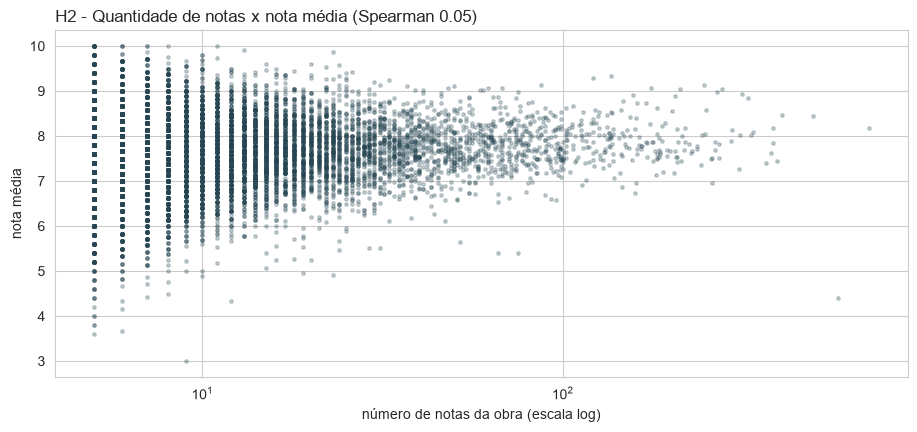

In [12]:
por_obra = notas.dropna(subset=['id_obra']).groupby('id_obra')['nota'].agg(n_notas='size', nota_media='mean')
base_h2 = por_obra[por_obra['n_notas'] >= 5]
h2 = teste_spearman(base_h2['n_notas'], base_h2['nota_media'])
pearson_v1 = por_obra['n_notas'].corr(por_obra['nota_media'])
print(f"Obras com 5 notas ou mais: {len(base_h2):,} | Spearman = {h2['tamanho do efeito']:.3f} (p = {h2['p-valor']:.1e})")
print(f'Pearson em todas as obras (o que a v1 calculou): {pearson_v1:.3f}')
faixas = pd.cut(base_h2['n_notas'], [4, 9, 19, 49, 10_000], labels=['5-9', '10-19', '20-49', '50+'])
display(base_h2.groupby(faixas, observed=True)['nota_media'].agg(['size', 'median']).round(2).rename(
    columns={'size': 'obras', 'median': 'mediana da nota média'}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(base_h2['n_notas'], base_h2['nota_media'], s=6, alpha=0.25, color='#264653')
ax.set_xscale('log')
ax.set_xlabel('número de notas da obra (escala log)')
ax.set_ylabel('nota média')
ax.set_title(f"H2 - Quantidade de notas x nota média (Spearman {h2['tamanho do efeito']:.2f})", loc='left')
salvar_figura('H2 - Quantidade de notas x nota media')
plt.show()
resultados_h['H2'] = h2['tamanho do efeito']

❌ **H2 rejeitada:** quase não há relação entre o número de notas e a nota média (Spearman de **0,046** nas **13.535** obras com 5 notas ou mais). A mediana da nota média vai de **7,62** (5 a 9 notas) a **7,81** (50 ou mais).

🧪 **Teste estatístico:** Spearman, p = 9,6e-08. "Significativo", mas o efeito é desprezível.

➡️ A conclusão da v1 se mantém, agora com o teste adequado: a v1 usou a correlação de Pearson (**0,019**), sensível à cauda longa do número de notas.

#### H3 - Quem avalia mais livros dá notas menores

In [13]:
por_leitor = notas.groupby('id_usuario')['nota'].agg(n_notas='size', nota_media='mean')
base_h3 = por_leitor[por_leitor['n_notas'] >= 5]
h3 = teste_spearman(base_h3['n_notas'], base_h3['nota_media'])
faixas = pd.cut(base_h3['n_notas'], [4, 9, 19, 49, 100_000], labels=['5-9', '10-19', '20-49', '50+'])
print(f"Usuários com 5 notas ou mais: {len(base_h3):,} | Spearman = {h3['tamanho do efeito']:.3f} (p = {h3['p-valor']:.1e})")
resultados_h['H3'] = h3['tamanho do efeito']
base_h3.groupby(faixas, observed=True)['nota_media'].agg(['size', 'median']).round(2).rename(
    columns={'size': 'usuários', 'median': 'mediana da nota média'})

Usuários com 5 notas ou mais: 14,220 | Spearman = 0.112 (p = 1.2e-40)


,usuários,mediana da nota média
n_notas,,
5-9,6886,7.40
10-19,3630,7.44
20-49,2372,7.64
50+,1332,7.80


❌ **H3 rejeitada, e no sentido contrário:** quem avalia mais livros dá notas um pouco **maiores** (Spearman de **0,112** em **14.220** usuários com 5 notas ou mais). A mediana da nota média sobe de **7,40** (5 a 9 notas) para **7,80** (50 ou mais).

🧪 **Teste estatístico:** Spearman, p = 1,2e-40. Efeito pequeno.

#### H4 - Leitores dos EUA dão notas diferentes

In [14]:
eua = notas['pais'] == 'usa'
h4 = teste_mann_whitney(notas.loc[eua, 'nota'], notas.loc[~eua & notas['pais'].notna(), 'nota'])
print(f"Notas dos EUA: {eua.sum():,} ({eua.mean():.1%}) | correlação de postos = {h4['tamanho do efeito']:.3f} "
      f"(p = {h4['p-valor']:.1e})")
resultados_h['H4'] = h4['tamanho do efeito']
notas.assign(grupo=np.where(eua, 'EUA', 'outros países')).loc[notas['pais'].notna()].groupby('grupo')['nota'].agg(
    ['size', 'mean', 'median']).round(2)

Notas dos EUA: 269,542 (62.2%) | correlação de postos = 0.069 (p = 2.6e-300)


,size,mean,median
grupo,,,
EUA,269542,7.68,8.0
outros países,143579,7.48,8.0


⚠️ **H4 com efeito desprezível:** as notas dos EUA (**62,2%** das notas) têm média de **7,68**, contra **7,48** nos outros países, e a mediana é **8** nos dois grupos.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos de **0,069** (p = 2,6e-300). O p minúsculo vem do tamanho da amostra; o efeito é muito pequeno.

### 3.3. Hipóteses Combinadas

#### H5 - A idade se relaciona com a nota

In [15]:
base_h5 = notas[notas['idade'].between(5, 100)]
h5 = teste_spearman(base_h5['idade'], base_h5['nota'])
faixas = pd.cut(base_h5['idade'], [4, 19, 29, 39, 49, 59, 100], labels=['5-19', '20-29', '30-39', '40-49', '50-59', '60+'])
print(f"Notas com idade válida (5 a 100): {len(base_h5):,} | Spearman = {h5['tamanho do efeito']:.3f} (p = {h5['p-valor']:.1e})")
resultados_h['H5'] = h5['tamanho do efeito']
base_h5.groupby(faixas, observed=True)['nota'].agg(['size', 'mean']).round(2).rename(columns={'size': 'notas', 'mean': 'nota média'})

Notas com idade válida (5 a 100): 303,100 | Spearman = 0.023 (p = 1.0e-36)


,notas,nota média
idade,,
5-19,18333,7.66
20-29,81287,7.72
30-39,94268,7.61
40-49,59383,7.73
50-59,37064,7.90
60+,12765,7.76


❌ **H5 rejeitada:** a idade quase não se relaciona com a nota (Spearman de **0,023** em **303.100** notas com idade válida). A nota média fica entre **7,61** e **7,90** em todas as faixas.

🧪 **Teste estatístico:** Spearman, p = 1,0e-36. Efeito desprezível, o que reforça a decisão de deixar a idade fora do modelo.

#### H6 - Livros mais recentes recebem notas maiores

In [16]:
base_h6 = notas[notas['ano'].between(1950, 2004)]
h6 = teste_spearman(base_h6['ano'], base_h6['nota'])
faixas = pd.cut(base_h6['ano'], [1949, 1979, 1989, 1994, 1999, 2004], labels=['1950-79', '1980-89', '1990-94', '1995-99', '2000-04'])
print(f"Notas de livros de 1950 a 2004: {len(base_h6):,} | Spearman = {h6['tamanho do efeito']:.3f} (p = {h6['p-valor']:.1e})")
resultados_h['H6'] = h6['tamanho do efeito']
base_h6.groupby(faixas, observed=True)['nota'].agg(['size', 'mean']).round(2).rename(columns={'size': 'notas', 'mean': 'nota média'})

Notas de livros de 1950 a 2004: 377,666 | Spearman = 0.007 (p = 1.3e-05)


,notas,nota média
ano,,
1950-79,12293,7.83
1980-89,47292,7.66
1990-94,64136,7.61
1995-99,116046,7.57
2000-04,137899,7.66


❌ **H6 rejeitada:** o ano de publicação não se relaciona com a nota (Spearman de **0,007** em **377.666** notas). Os livros mais antigos (1950 a 1979) têm até a maior média, **7,83**.

🧪 **Teste estatístico:** Spearman, p = 1,3e-05. Efeito nulo.

#### H7 - Quem leu Harry Potter 1 tem muito mais chance de ler o 2

In [17]:
leitores_hp1 = set(interacoes.loc[interacoes['id_obra'].str.startswith('harry potter and the sorcerers stone'), 'id_usuario'])
leitores_hp2 = set(interacoes.loc[interacoes['id_obra'].str.startswith('harry potter and the chamber of secrets'), 'id_usuario'])
todos = interacoes['id_usuario'].unique()
leu_hp1, leu_hp2 = np.isin(todos, list(leitores_hp1)), np.isin(todos, list(leitores_hp2))
h7 = teste_qui_quadrado(leu_hp1, leu_hp2)
razao = odds_ratio(leu_hp1, leu_hp2)
print(f'Leitores do 1: {leu_hp1.sum():,} | do 2: {leu_hp2.sum():,} | de todos os usuários: {len(todos):,}')
print(f'Chance de ler o 2: {leu_hp2[leu_hp1].mean():.1%} entre quem leu o 1 x {leu_hp2[~leu_hp1].mean():.2%} entre os demais')
print(f"V de Cramér = {h7['tamanho do efeito']:.3f} | odds ratio = {razao:.0f} (p = {h7['p-valor']:.1e})")
resultados_h['H7'] = razao

Leitores do 1: 839 | do 2: 591 | de todos os usuários: 92,106
Chance de ler o 2: 41.6% entre quem leu o 1 x 0.27% entre os demais
V de Cramér = 0.491 | odds ratio = 268 (p = 0.0e+00)


✅ **H7 confirmada, com efeito enorme:** entre quem leu *Harry Potter 1*, **41,6%** leram o 2; entre os demais, só **0,27%**. A chance é **268 vezes** maior (V de Cramér de **0,491**).

🧪 **Teste estatístico:** qui-quadrado (p ≈ 0) + V de Cramér + odds ratio.

➡️ É a base da filtragem colaborativa: livros são lidos em conjunto (séries, autores, gêneros), e quem leu um tende a ler o outro.

#### H8 - Ser muito lido não significa ser bem avaliado

,leitores,n_notas,nota_media,% sem nota
id_obra,,,,
wild animus | richshapero,2502,581,4.39,0.77
the lovely bones a novel | alicesebold,1295,707,8.19,0.45
the da vinci code | danbrown,897,494,8.44,0.45
divine secrets of the yaya sisterhood a novel | rebeccawells,853,382,7.84,0.55
the nanny diaries a novel | emmamclaughlin,821,393,7.44,0.52


Wild Animus: 581 notas, média 4.39 x 7.88 nos outros 49 livros mais lidos | correlação de postos = -0.743 (p = 2.0e-209)


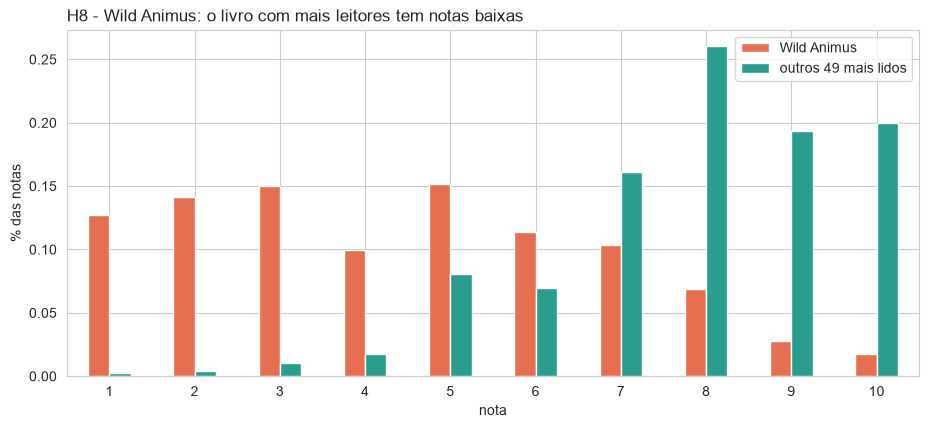

In [18]:
leitores_obra = interacoes.groupby('id_obra').size().sort_values(ascending=False)
mais_lidos = pd.DataFrame({'leitores': leitores_obra.head(5)}).join(por_obra)
mais_lidos['% sem nota'] = 1 - mais_lidos['n_notas'] / mais_lidos['leitores']
display(mais_lidos.round(2))

wild = notas['id_obra'] == 'wild animus | richshapero'
populares = notas['id_obra'].isin(leitores_obra.head(50).index) & ~wild
h8 = teste_mann_whitney(notas.loc[wild, 'nota'], notas.loc[populares, 'nota'])
print(f"Wild Animus: {wild.sum()} notas, média {notas.loc[wild, 'nota'].mean():.2f} x {notas.loc[populares, 'nota'].mean():.2f} "
      f"nos outros 49 livros mais lidos | correlação de postos = {h8['tamanho do efeito']:.3f} (p = {h8['p-valor']:.1e})")
resultados_h['H8'] = h8['tamanho do efeito']

fig, ax = plt.subplots(figsize=(11, 4.5))
distribuicao = pd.DataFrame({'Wild Animus': notas.loc[wild, 'nota'].value_counts(normalize=True),
                             'outros 49 mais lidos': notas.loc[populares, 'nota'].value_counts(normalize=True)}).sort_index()
distribuicao.plot.bar(ax=ax, color=['#e76f51', '#2a9d8f'], rot=0)
ax.set_xlabel('nota')
ax.set_ylabel('% das notas')
ax.set_title('H8 - Wild Animus: o livro com mais leitores tem notas baixas', loc='left')
salvar_figura('H8 - Wild Animus')
plt.show()

✅ **H8 confirmada:** *Wild Animus* é a obra com mais leitores (**2.502**), quase o dobro da 2ª (*The Lovely Bones*, **1.295**), mas tem nota média de **4,39**, contra **7,88** nos outros 49 livros mais lidos. **77%** dos seus leitores não deram nota.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos de **−0,743** (p = 2,0e-209). Efeito grande.

➡️ O livro foi distribuído de graça como divulgação, o que explica tantos "leitores" sem nota e notas tão baixas. Um recomendador que conta leitores vai empurrá-lo para todo mundo: a Fase 03 (item 7.2) mede isso e cria um filtro de qualidade.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Teste | Tamanho do efeito |
|---|---|---|---|---|
| H1 | A maioria das interações não tem nota | ✅ Confirmada | Binomial | **62,3%** sem nota |
| H2 | Mais notas → nota média maior | ❌ Rejeitada | Spearman | rho **0,046** |
| H3 | Quem avalia mais é mais crítico | ❌ Rejeitada (efeito contrário e pequeno) | Spearman | rho **0,112** |
| H4 | Notas dos EUA são diferentes | ⚠️ Desprezível | Mann-Whitney | postos **0,069** |
| H5 | A idade se relaciona com a nota | ❌ Rejeitada | Spearman | rho **0,023** |
| H6 | Livros recentes têm notas maiores | ❌ Rejeitada | Spearman | rho **0,007** |
| H7 | Quem leu HP 1 lê o 2 | ✅ Confirmada (enorme) | Qui-quadrado + odds ratio | OR **268**, V **0,491** |
| H8 | Muito lido ≠ bem avaliado | ✅ Confirmada | Mann-Whitney | postos **−0,743** |

➡️ As características do leitor e do livro (país, idade, ano, popularidade) quase não explicam a nota. O que tem efeito forte é **o que se lê junto** (H7). Por isso a solução é filtragem colaborativa.

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

Num recomendador colaborativo, os "atributos" são as **interações usuário × livro**. Três decisões:

1. **Obra = título + autor normalizados:** junta as edições de um mesmo livro e separa livros diferentes com o mesmo título (`criar_obras`, item 2.2).
2. **Uma interação por usuário × obra:** quem tem duas edições do mesmo livro fica com a maior nota (`montar_interacoes`).
3. **Catálogo:** obras com pelo menos **50 notas explícitas** (o mesmo corte da v1), para que a similaridade entre livros tenha dados suficientes (`montar_catalogo`).

In [19]:
no_catalogo_isbn = avaliacoes['isbn'].isin(livros['isbn']).sum()
print(f'Interações usuário × ISBN (com ISBN no cadastro): {no_catalogo_isbn:,} -> usuário × obra: {len(interacoes):,} '
      f'({no_catalogo_isbn - len(interacoes):,} eram edições repetidas da mesma obra)')

catalogo = montar_catalogo(interacoes, livros, avaliacoes)
itens = catalogo.index.to_numpy()
nomes = catalogo['titulo'].to_numpy()
no_catalogo = interacoes[interacoes['id_obra'].isin(itens)].reset_index(drop=True)
print(f"Obras no catálogo: {len(catalogo)} (v1: 651 títulos) | interações: {len(no_catalogo):,} | "
      f"com nota: {no_catalogo['explicita'].sum():,} | gostou (nota >= 7): {(no_catalogo['nota'] >= NOTA_GOSTOU).sum():,}")
print(f"Usuários: {no_catalogo['id_usuario'].nunique():,} | densidade da matriz: "
      f"{len(no_catalogo) / (len(catalogo) * no_catalogo['id_usuario'].nunique()):.3%}")
catalogo.head(10)[['titulo', 'autor', 'ano', 'n_notas', 'nota_media', 'n_leitores']].round(2)

Interações usuário × ISBN (com ISBN no cadastro): 1,031,136 -> usuário × obra: 1,026,706 (4,430 eram edições repetidas da mesma obra)


Obras no catálogo: 642 (v1: 651 títulos) | interações: 150,275 | com nota: 65,344 | gostou (nota >= 7): 52,455
Usuários: 35,339 | densidade da matriz: 0.662%


,titulo,autor,ano,n_notas,nota_media,n_leitores
id_obra,,,,,,
the lovely bones a novel | alicesebold,The Lovely Bones: A Novel,Alice Sebold,2002,707,8.19,1295
wild animus | richshapero,Wild Animus,Rich Shapero,2004,581,4.39,2502
the da vinci code | danbrown,The Da Vinci Code,Dan Brown,2003,494,8.44,897
the secret life of bees | suemonkkidd,The Secret Life of Bees,Sue Monk Kidd,2003,402,8.48,762
the nanny diaries a novel | emmamclaughlin,The Nanny Diaries: A Novel,Emma McLaughlin,2002,391,7.43,821
the red tent bestselling backlist | anitadiamant,The Red Tent (Bestselling Backlist),Anita Diamant,1998,383,8.18,723
divine secrets of the yaya sisterhood a novel | rebeccawells,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,1997,380,7.83,853
bridget joness diary | helenfielding,Bridget Jones's Diary,Helen Fielding,1999,367,7.65,772
a painted house | johngrisham,A Painted House,John Grisham,2001,363,7.39,818


📌 **Nota: interações e catálogo**
- 🔎 **4.430** interações eram edições repetidas da mesma obra pelo mesmo usuário e foram unidas.
- 🔎 O catálogo tem **642** obras com 50 notas ou mais (a v1 tinha 651 títulos), com **150.275** interações de **35.339** usuários. Dessas interações, **65.344** têm nota e **52.455** são "gostou".
- 🔎 A matriz usuário × livro tem só **0,662%** das células preenchidas: cada usuário conhece uma fração mínima do catálogo.

## 5 - EXPLORANDO AS CORRELAÇÕES

,n_leitores,n_notas,nota_media,ano,pct_sem_nota
n_leitores,1.00,0.91,-0.07,-0.03,0.18
n_notas,0.91,1.00,0.10,-0.01,-0.19
nota_media,-0.07,0.10,1.00,-0.17,-0.45
ano,-0.03,-0.01,-0.17,1.00,-0.07
pct_sem_nota,0.18,-0.19,-0.45,-0.07,1.00


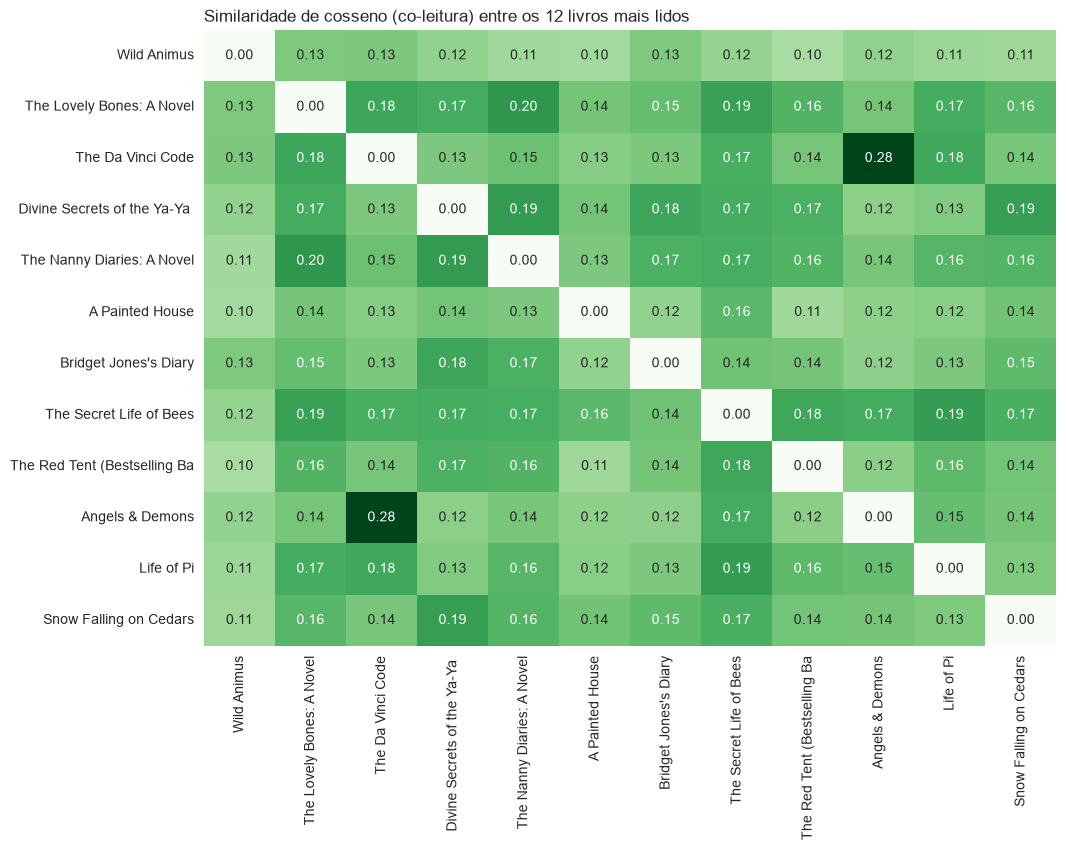

,livro A,livro B,cosseno
0,"Key of Valor (Roberts, Nora. Key Trilogy, 3.)",Key of Knowledge (Key Trilogy (Paperback)),0.762
1,Key of Light (Key Trilogy (Paperback)),Key of Knowledge (Key Trilogy (Paperback)),0.753
2,"Key of Valor (Roberts, Nora. Key Trilogy, 3.)",Key of Light (Key Trilogy (Paperback)),0.699
3,"The Two Towers (The Lord of the Rings, Part 2)","The Return of the King (The Lord of the Rings, Part 3)",0.649
4,Tribulation Force: The Continuing Drama of Those Left Behind (Left...,Nicolae: The Rise of Antichrist (Left Behind No. 3),0.634
5,"The Subtle Knife (His Dark Materials, Book 2)","The Amber Spyglass (His Dark Materials, Book 3)",0.611
6,Four To Score (A Stephanie Plum Novel),High Five (A Stephanie Plum Novel),0.604
7,Guilty Pleasures (Anita Blake Vampire Hunter (Paperback)),The Laughing Corpse (Anita Blake Vampire Hunter (Paperback)),0.593


In [20]:
# Correlações entre as características dos livros do catálogo
caracteristicas = catalogo[['n_leitores', 'n_notas', 'nota_media', 'ano']].assign(
    pct_sem_nota=1 - catalogo['n_notas'] / catalogo['n_leitores'])
caracteristicas['ano'] = caracteristicas['ano'].where(caracteristicas['ano'] > 0)
display(caracteristicas.corr(method='spearman').round(2))

# Co-leitura (similaridade de cosseno) entre os 12 livros com mais leitores: quanto os mesmos usuários leem os dois
usuarios_catalogo = np.sort(no_catalogo['id_usuario'].unique())
similaridade = VizinhosItens('cosseno').fit(matriz_usuario_item(no_catalogo, usuarios_catalogo, itens)).W
top12 = np.argsort(-catalogo['n_leitores'].to_numpy())[:12]
rotulos = [t[:28] for t in nomes[top12]]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(pd.DataFrame(similaridade[np.ix_(top12, top12)], index=rotulos, columns=rotulos), annot=True, fmt='.2f',
            cmap='Greens', cbar=False, ax=ax)
ax.set_title('Similaridade de cosseno (co-leitura) entre os 12 livros mais lidos', loc='left')
salvar_figura('Similaridade entre livros')
plt.show()

i, j = np.triu_indices(len(itens), k=1)
pares = pd.DataFrame({'livro A': nomes[i], 'livro B': nomes[j], 'cosseno': similaridade[i, j]})
pares.nlargest(8, 'cosseno').round(3).reset_index(drop=True)

📌 **Nota: correlações**
- 🔎 Entre as características dos livros, a nota média se relaciona sobretudo com a **% de interações sem nota** (Spearman de **−0,45**): livros que muita gente registra sem avaliar tendem a ter nota menor (*Wild Animus* é o caso extremo). O número de leitores quase não se relaciona com a nota (**−0,07**).
- 🔎 Os pares com maior co-leitura são **volumes de uma mesma série**: *Key Trilogy* de Nora Roberts (cosseno de **0,762**), *O Senhor dos Anéis* (**0,649**), *Left Behind*, *His Dark Materials*. É a H7 vista no catálogo inteiro.
- ⚠️ Esta análise usa todas as interações e serve só para conhecer os dados. Os modelos da Fase 03 aprendem apenas com o treino.

# FASE 03: MODELAGEM DOS DADOS

## 1 - Leitura dos dados

In [21]:
print(f'Interações no catálogo: {no_catalogo.shape} | catálogo: {catalogo.shape}')
no_catalogo.head()

Interações no catálogo: (150275, 4) | catálogo: (642, 9)


,id_usuario,id_obra,nota,explicita
0,33681,balzac and the little chinese seamstress a novel | daisijie,10,True
1,276680,mystic river | dennislehane,10,True
2,276681,brave new world | aldoushuxley,10,True
3,276680,middlesex a novel | jeffreyeugenides,10,True
4,276680,the corrections a novel | jonathanfranzen,10,True


📌 **Nota:** a modelagem usa as **150.275** interações das **642** obras do catálogo, uma linha por usuário × obra, com a nota (0 = sem nota).

## 2 - Valores nulos

In [22]:
display(no_catalogo.isna().sum().to_frame('nulos').T)
catalogo[['titulo', 'autor', 'ano', 'capa_m', 'capa_g']].isna().sum().to_frame('nulos no catálogo').T

,id_usuario,id_obra,nota,explicita
nulos,0,0,0,0


,titulo,autor,ano,capa_m,capa_g
nulos no catálogo,0,0,0,0,0


📌 **Nota:** nenhum nulo nas interações nem no catálogo (título, autor, ano e capa preenchidos para as 642 obras).

## 3 - Transformação

Os modelos recebem uma **matriz esparsa usuários × livros**, com 1 onde o usuário tem o livro (`matriz_usuario_item`). Qual interação vira 1 é uma escolha (`filtrar_sinal`), testada no ajuste fino (item 7):

| Sinal | Interações usadas no treino |
|---|---|
| `gostou` | só notas ≥ 7 |
| `explicitas` | todas as notas de 1 a 10 (o que a v1 usava) |
| `todas` | também as interações sem nota |

In [23]:
for sinal in ['gostou', 'explicitas', 'todas']:
    X = matriz_usuario_item(filtrar_sinal(no_catalogo, sinal), usuarios_catalogo, itens)
    print(f'{sinal:>10}: {X.nnz:>7,} interações | densidade {X.nnz / np.prod(X.shape):.4%} | '
          f'usuários com alguma interação: {(X.getnnz(axis=1) > 0).sum():,}')

    gostou:  52,455 interações | densidade 0.2312% | usuários com alguma interação: 21,248


explicitas:  65,344 interações | densidade 0.2880% | usuários com alguma interação: 24,979


     todas: 150,275 interações | densidade 0.6624% | usuários com alguma interação: 35,339


📌 **Nota: sinais**
- 🔎 Usar todas as interações mais que dobra a informação: são **150.275**, contra **65.344** só com notas explícitas, e **35.339** usuários com alguma interação, contra **24.979**.
- ✅ **Decisão:** a Fase 03, item 7, escolhe o sinal na validação.

## 4 - Pré-Processamento

### 4.1. Separação dos dados

In [24]:
conjunto = separar_por_usuario(no_catalogo, min_gostou=MIN_GOSTOU_AVALIACAO, semente=SEMENTE)
separacao = no_catalogo.groupby(conjunto).agg(interações=('id_obra', 'size'), usuários=('id_usuario', 'nunique'))
gostou_avaliados = no_catalogo[(no_catalogo['nota'] >= NOTA_GOSTOU)
                               & no_catalogo['id_usuario'].isin(no_catalogo.loc[conjunto == 'teste', 'id_usuario'])]
separacao['% dos livros que os avaliados gostaram'] = (
    gostou_avaliados.groupby(conjunto[gostou_avaliados.index]).size() / len(gostou_avaliados)).round(3)
print(f"Usuários avaliados (>= {MIN_GOSTOU_AVALIACAO} livros de que gostaram): "
      f"{no_catalogo.loc[conjunto == 'teste', 'id_usuario'].nunique():,}")
separacao.loc[['treino', 'validacao', 'teste']]

Usuários avaliados (>= 5 livros de que gostaram): 2,311


,interações,usuários,% dos livros que os avaliados gostaram
treino,140201,35339,0.607
validacao,5037,2311,0.196
teste,5037,2311,0.196


📌 **Nota: separação 60/20/20 por usuário**
- 🔎 **2.311** usuários têm 5 ou mais livros de que gostaram e entram na avaliação. Os livros de que eles gostaram ficaram **60,7% / 19,6% / 19,6%** em treino, validação e teste (**5.037** livros escondidos em cada).
- 🔎 Todos os **35.339** usuários estão no treino: quem tem poucos livros ou só interações sem nota não é avaliado, mas ensina ao modelo quais livros são lidos juntos.
- ⚠️ A base não tem datas, então a separação é aleatória dentro de cada usuário (não dá para "prever o próximo livro" no tempo).

### 4.2. Balancear os dados

🚫 **Não se aplica.** O recomendador ordena livros para cada usuário; não há classes a equilibrar. A popularidade desigual dos livros (poucos best-sellers, muitos livros pouco lidos) é tratada na avaliação: a **cobertura** e a **popularidade média** das listas mostram se o modelo só recomenda best-sellers.

### 4.3. Seleção de Variáveis

🚫 **Não se aplica.** A filtragem colaborativa não usa variáveis dos livros ou dos usuários, só a matriz de interações; não há colunas para o Random Forest e a Informação Mútua ordenarem. A "seleção" equivalente é o corte do catálogo (≥ 50 notas, item 4 da Fase 02) e a escolha do sinal (item 7).

## 5 - Treinamento dos Algoritmos de Machine Learning

Todos os modelos treinam com o **sinal `explicitas`** (as notas de 1 a 10, como na v1) e são medidos na **validação**: para cada usuário avaliado, os livros escondidos devem aparecer entre os 10 recomendados (os livros que ele já tem nunca são recomendados de novo).

| Métrica | O que mede |
|---|---|
| **acerto@10** | % de usuários com pelo menos 1 livro escondido na lista (a principal) |
| **precisão@10** | dos 10 recomendados, quantos o usuário gostou |
| **recall@10** | dos livros escondidos, quantos a lista encontrou |
| **NDCG@10** | como o recall, mas vale mais acertar no topo da lista |
| **cobertura** | % do catálogo que aparece em alguma lista |
| **popularidade média** | % de usuários que leram os livros recomendados (alta = só best-sellers) |

> 🚫 **Treino × validação (sobreajuste):** num recomendador, os livros do treino são justamente os excluídos da lista, então não há "acerto no treino" para comparar. O sobreajuste aparece no ajuste fino (item 7), quando a penalização do EASE fica pequena demais.

In [25]:
X_treino, X_hist_val, X_val = montar_matrizes(no_catalogo, conjunto, itens, lambda d: filtrar_sinal(d, 'explicitas'))
X_treino_notas, X_hist_val_notas, _ = montar_matrizes(no_catalogo, conjunto, itens,
                                                      lambda d: filtrar_sinal(d, 'explicitas'), valor='nota')
X_leitores, _, _ = montar_matrizes(no_catalogo, conjunto, itens)
popularidade = np.asarray((X_leitores > 0).mean(axis=0)).ravel()  # % dos usuários que leram cada livro (no treino)
usuario_exemplo = 0  # o mesmo usuário em todas as amostras gabarito x previsão
resultados = {}


def treinar_e_avaliar(nome, modelo, X=None, X_hist=None):
    """Treina na matriz de treino, mede na validação e guarda o resumo em `resultados`."""
    modelo.fit(X_treino if X is None else X)
    resumo, _ = avaliar_recomendador(modelo, X_hist_val if X_hist is None else X_hist, X_val, popularidade=popularidade)
    resultados[nome] = resumo
    display(pd.DataFrame([resumo], index=[nome]).round(4))
    return modelo


print(f'Matriz de treino: {X_treino.shape} | usuários avaliados na validação: {X_val.shape[0]:,} | '
      f'livros escondidos: {X_val.nnz:,}')

Matriz de treino: (35339, 642) | usuários avaliados na validação: 2,311 | livros escondidos: 5,037


### Aleatório (o piso)

In [26]:
aleatorio = treinar_e_avaliar('Aleatório', Aleatorio())
comparar_lista(aleatorio, X_hist_val, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
Aleatório,0.035,0.0035,0.0154,0.0088,1.0,0.0061


,livro recomendado,gostou (escondido)?
posição,,
1,Phantoms,
2,The Jester,
3,The Search,
4,I Know This Much Is True,
5,American Psycho (Vintage Contemporaries),
6,How to Make an American Quilt,
7,Rebecca,
8,The Wailing Wind,
9,Mr. Maybe,


### Popularidade (o "modelo que chuta")

In [27]:
popular = treinar_e_avaliar('Popularidade', Popularidade())
comparar_lista(popular, X_hist_val, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
Popularidade,0.1108,0.0122,0.0591,0.0355,0.0327,0.0267


,livro recomendado,gostou (escondido)?
posição,,
1,The Lovely Bones: A Novel,
2,Wild Animus,
3,The Da Vinci Code,
4,The Nanny Diaries: A Novel,
5,The Red Tent (Bestselling Backlist),
6,The Secret Life of Bees,
7,Divine Secrets of the Ya-Ya Sisterhood: A Novel,
8,Bridget Jones's Diary,
9,Girl with a Pearl Earring,


### Vizinhos euclidianos (a configuração da v1)

In [28]:
# Como na v1: notas de 1 a 10 nas colunas e distância euclidiana (o zero de "não leu" entra na conta)
euclidiano = treinar_e_avaliar('Vizinhos euclidianos (v1)', VizinhosItens('euclidiana'), X_treino_notas, X_hist_val_notas)
comparar_lista(euclidiano, X_hist_val_notas, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
Vizinhos euclidianos (v1),0.0381,0.004,0.0195,0.0125,0.0654,0.0038


,livro recomendado,gostou (escondido)?
posição,,
1,4 Blondes,
2,Don't Stand Too Close to a Naked Man,
3,Four Blondes,
4,Full Tilt (Janet Evanovich's Full Series),
5,"The Reptile Room (A Series of Unfortunate Events, Book 2)",
6,Key of Knowledge (Key Trilogy (Paperback)),
7,"Breath, Eyes, Memory",
8,Isle of Dogs,
9,The Pilot's Wife,


### Vizinhos por cosseno

In [29]:
cosseno = treinar_e_avaliar('Vizinhos cosseno', VizinhosItens('cosseno'))
comparar_lista(cosseno, X_hist_val, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
Vizinhos cosseno,0.2722,0.0337,0.1686,0.1185,0.8723,0.0074


,livro recomendado,gostou (escondido)?
posição,,
1,Midwives: A Novel,
2,We Were the Mulvaneys,
3,Pet Sematary,
4,The Book of Ruth (Oprah's Book Club (Paperback)),
5,STONES FROM THE RIVER,
6,The Bluest Eye,
7,Jewel,
8,House of Sand and Fog,
9,Hannibal,


### Fatoração (SVD)

In [30]:
svd = treinar_e_avaliar('Fatoração SVD', FatoracaoSVD(n_componentes=50, semente=SEMENTE))
comparar_lista(svd, X_hist_val, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
Fatoração SVD,0.2025,0.0248,0.118,0.0785,0.4361,0.0107


,livro recomendado,gostou (escondido)?
posição,,
1,We Were the Mulvaneys,
2,The Brethren,
3,While I Was Gone,
4,Midwives: A Novel,
5,Fahrenheit 451,
6,Harry Potter and the Order of the Phoenix (Book 5),
7,Good in Bed,
8,Suzanne's Diary for Nicholas,
9,ANGELA'S ASHES,


### EASE

In [31]:
ease = treinar_e_avaliar('EASE', EASE(lambda_=500))
comparar_lista(ease, X_hist_val, X_val, usuario_exemplo, nomes)

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,popularidade média
EASE,0.3107,0.0392,0.1976,0.1345,0.7227,0.0138


,livro recomendado,gostou (escondido)?
posição,,
1,We Were the Mulvaneys,
2,The Red Tent (Bestselling Backlist),
3,Divine Secrets of the Ya-Ya Sisterhood: A Novel,
4,Midwives: A Novel,
5,The Lovely Bones: A Novel,
6,House of Sand and Fog,
7,Bridget Jones's Diary,
8,The Summons,
9,The Brethren,


📌 **Nota: os 6 recomendadores na validação (sinal: notas explícitas)**

| Modelo | acerto@10 | Leitura |
|---|---|---|
| Aleatório | **3,5%** | O piso: sortear 10 dos 642 livros |
| Popularidade | **11,1%** | Os mesmos 10 best-sellers para todo mundo (cobertura de **3,3%** do catálogo), incluindo *Wild Animus* em 2º |
| Vizinhos euclidianos (v1) | **3,8%** | **Praticamente o sorteio**: com zeros onde o usuário não leu, a distância euclidiana aproxima livros pouco lidos (*4 Blondes*, *Don't Stand Too Close to a Naked Man*) |
| Vizinhos por cosseno | **27,2%** | O cosseno compara o padrão de leitores, não a quantidade de zeros |
| Fatoração SVD | **20,2%** | Concentra as listas em menos livros (cobertura de **43,6%**) |
| EASE | **31,1%** | O melhor: quase o triplo da popularidade |

- ⚠️ A versão original usava a distância euclidiana sem medir o acerto. ✅ Na v2, essa configuração acerta **3,8%**, contra **3,5%** do sorteio. O exemplo de Harry Potter parecia bom porque os volumes da série têm muitos leitores em comum, mas a média de acerto mostra que o método não funciona para o resto do catálogo.
- 🔎 No usuário de exemplo, nenhum modelo acertou os livros escondidos dele. Os exemplos com acerto estão na Fase 04.

### Validação cruzada

Uma única separação pode favorecer um modelo por sorte. Repetimos a separação 60/20/20 com **5 sementes** e medimos todos os modelos em cada uma: média ± desvio.

In [32]:
fabricas = {'Aleatório': lambda: Aleatorio(), 'Popularidade': lambda: Popularidade(),
            'Vizinhos euclidianos (v1)': lambda: VizinhosItens('euclidiana'),
            'Vizinhos cosseno': lambda: VizinhosItens('cosseno'),
            'Fatoração SVD': lambda: FatoracaoSVD(n_componentes=50, semente=SEMENTE), 'EASE': lambda: EASE(lambda_=500)}
repeticoes = []
for semente in SEMENTES_VALIDACAO:
    conjunto_s = separar_por_usuario(no_catalogo, min_gostou=MIN_GOSTOU_AVALIACAO, semente=semente)
    matrizes = montar_matrizes(no_catalogo, conjunto_s, itens, lambda d: filtrar_sinal(d, 'explicitas'))
    matrizes_notas = montar_matrizes(no_catalogo, conjunto_s, itens, lambda d: filtrar_sinal(d, 'explicitas'), valor='nota')
    for nome, fabrica in fabricas.items():
        X_t, X_h, X_a = matrizes_notas if 'euclidianos' in nome else matrizes
        resumo, _ = avaliar_recomendador(fabrica().fit(X_t), X_h, X_a)
        repeticoes.append({'semente': semente, 'modelo': nome, **resumo})
repeticoes = pd.DataFrame(repeticoes)
validacao_cruzada = repeticoes.groupby('modelo', sort=False)[['acerto@10', 'ndcg@10']].agg(['mean', 'std'])
validacao_cruzada.round(4)

acerto@10         ndcg@10        
                               mean     std    mean     std
modelo                                                     
Aleatório                    0.0353  0.0005  0.0087  0.0004
Popularidade                 0.1137  0.0095  0.0347  0.0026
Vizinhos euclidianos (v1)    0.0348  0.0035  0.0118  0.0005
Vizinhos cosseno             0.2784  0.0069  0.1232  0.0040
Fatoração SVD                0.2122  0.0076  0.0855  0.0049
EASE                         0.3131  0.0060  0.1362  0.0010

📌 **Nota: separações repetidas**
- 🔎 Com 5 sementes, a ordem se mantém: EASE **31,3% ± 0,6%**, cosseno **27,8% ± 0,7%**, SVD **21,2% ± 0,8%**, popularidade **11,4% ± 0,9%**, euclidiano da v1 **3,5% ± 0,4%** e sorteio **3,5%**.
- 🔎 A distância entre o EASE e o cosseno é bem maior que o desvio de cada um: não é sorte da separação.

## 6 - Comparação do desempenho dos modelos

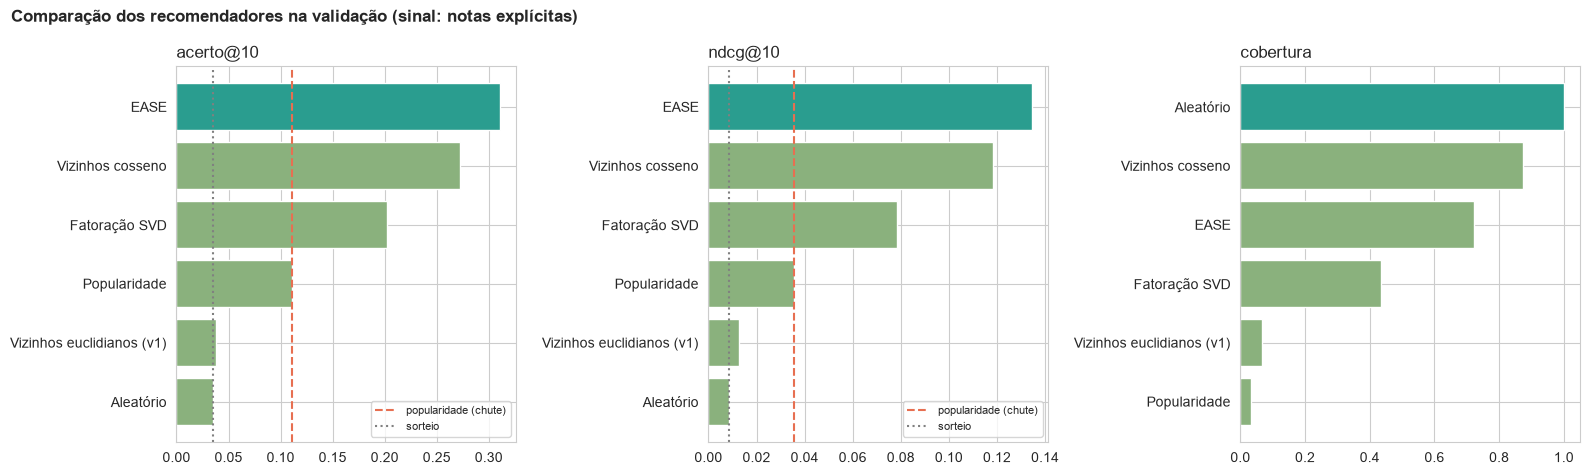

,acerto@10,precisão@10,recall@10,ndcg@10,cobertura,acerto@10 (5 separações),score geral
Aleatório,0.0350,0.0035,0.0154,0.0088,1.0000,0.035 ± 0.000,0.44
Popularidade,0.1108,0.0122,0.0591,0.0355,0.0327,0.114 ± 0.009,0.39
Vizinhos euclidianos (v1),0.0381,0.0040,0.0195,0.0125,0.0654,0.035 ± 0.003,0.33
Vizinhos cosseno,0.2722,0.0337,0.1686,0.1185,0.8723,0.278 ± 0.007,0.83
Fatoração SVD,0.2025,0.0248,0.1180,0.0785,0.4361,0.212 ± 0.008,0.61
EASE,0.3107,0.0392,0.1976,0.1345,0.7227,0.313 ± 0.006,0.89


In [33]:
comparacao = pd.DataFrame(resultados).T
comparacao['acerto@10 (5 separações)'] = [f"{validacao_cruzada.loc[n, ('acerto@10', 'mean')]:.3f} ± "
                                          f"{validacao_cruzada.loc[n, ('acerto@10', 'std')]:.3f}" for n in comparacao.index]
comparacao['score geral'] = comparacao[['acerto@10', 'ndcg@10', 'cobertura']].rank(pct=True).mean(axis=1).round(2)
comparacao.to_csv(PASTA_REPORTS / 'comparacao_modelos.csv')

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))
for eixo, metrica in zip(eixos, ['acerto@10', 'ndcg@10', 'cobertura']):
    valores = comparacao[metrica].astype(float).sort_values()
    eixo.barh(valores.index, valores, color=['#2a9d8f' if v == valores.max() else '#8ab17d' for v in valores])
    if metrica != 'cobertura':
        eixo.axvline(comparacao.loc['Popularidade', metrica], color='#e76f51', ls='--', label='popularidade (chute)')
        eixo.axvline(comparacao.loc['Aleatório', metrica], color='grey', ls=':', label='sorteio')
        eixo.legend(loc='lower right', fontsize=8)
    eixo.set_title(metrica, loc='left')
fig.suptitle('Comparação dos recomendadores na validação (sinal: notas explícitas)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
salvar_figura('Comparacao dos recomendadores')
plt.show()
comparacao.drop(columns='popularidade média').round(4)

📌 **Nota: comparação**
- 🔎 O **EASE** lidera em acerto@10 (**0,311**), precisão, recall e NDCG (**0,135**), com o maior score geral (**0,89**). O cosseno tem a maior cobertura entre os modelos úteis (**87,2%**), mas acerta menos.
- 🔎 Só o EASE, o cosseno e o SVD ficam bem acima da linha da popularidade; o euclidiano da v1 fica colado no sorteio.
- ✅ **Decisão:** o EASE e o cosseno seguem para o ajuste fino, junto com o SVD. A tabela está em `reports/comparacao_modelos.csv`.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

### 7.1. Busca em grade

Com poucos hiperparâmetros por modelo, testamos **todas** as combinações (busca em grade) na validação, incluindo o **sinal** usado no treino. O teste continua fechado.

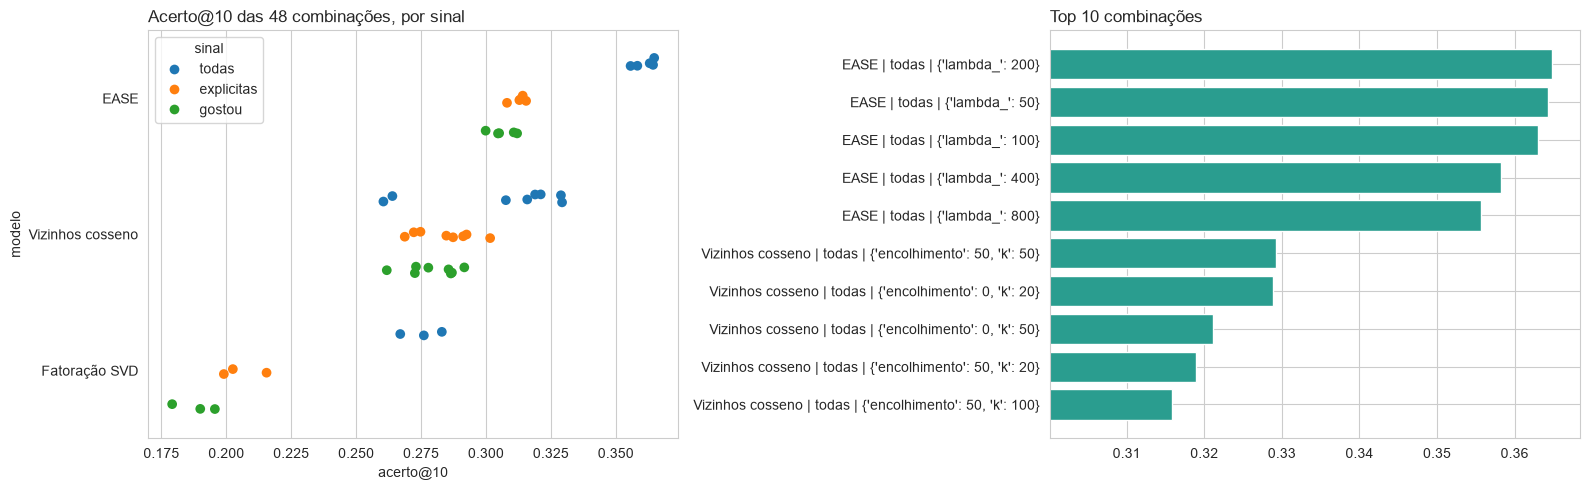

sinal,explicitas,gostou,todas
modelo,,,
EASE,0.3154,0.3120,0.3648
Fatoração SVD,0.2155,0.1956,0.2830
Vizinhos cosseno,0.3016,0.2916,0.3293


,modelo,sinal,parâmetros,acerto@10,precisão@10,recall@10,ndcg@10,cobertura
0,EASE,todas,{'lambda_': 200},0.3648,0.0471,0.2358,0.1604,0.8333
1,EASE,todas,{'lambda_': 50},0.3643,0.0471,0.2337,0.1609,0.9097
2,EASE,todas,{'lambda_': 100},0.3630,0.0472,0.2344,0.1606,0.8816
3,EASE,todas,{'lambda_': 400},0.3583,0.0462,0.2336,0.1580,0.7601
4,EASE,todas,{'lambda_': 800},0.3557,0.0451,0.2297,0.1522,0.6791


In [34]:
grades = {
    'Vizinhos cosseno': (lambda p: VizinhosItens('cosseno', k=p['k'], encolhimento=p['encolhimento']),
                         {'k': [20, 50, 100, None], 'encolhimento': [0, 50]}),
    'Fatoração SVD': (lambda p: FatoracaoSVD(n_componentes=p['n_componentes'], semente=SEMENTE),
                      {'n_componentes': [20, 50, 100]}),
    'EASE': (lambda p: EASE(lambda_=p['lambda_']), {'lambda_': [50, 100, 200, 400, 800]}),
}
busca = []
for sinal in ['gostou', 'explicitas', 'todas']:
    X_t, X_h, X_a = montar_matrizes(no_catalogo, conjunto, itens, lambda d: filtrar_sinal(d, sinal))
    for modelo, (fabrica, grade) in grades.items():
        for parametros in ParameterGrid(grade):
            resumo, _ = avaliar_recomendador(fabrica(parametros).fit(X_t), X_h, X_a)
            busca.append({'modelo': modelo, 'sinal': sinal, 'parâmetros': str(parametros),
                          'lambda_': parametros.get('lambda_'), **resumo})
busca = pd.DataFrame(busca).sort_values('acerto@10', ascending=False).reset_index(drop=True)
busca.to_csv(PASTA_REPORTS / 'busca_hiperparametros.csv', index=False)

fig, eixos = plt.subplots(1, 2, figsize=(16, 5))
sns.stripplot(data=busca, x='acerto@10', y='modelo', hue='sinal', dodge=True, size=7, ax=eixos[0])
eixos[0].set_title(f'Acerto@10 das {len(busca)} combinações, por sinal', loc='left')
top10 = busca.head(10)
eixos[1].barh([f"{m} | {s} | {p}" for m, s, p in zip(top10['modelo'], top10['sinal'], top10['parâmetros'])][::-1],
              top10['acerto@10'][::-1], color='#2a9d8f')
eixos[1].set_xlim(top10['acerto@10'].min() * 0.95, top10['acerto@10'].max() * 1.01)
eixos[1].set_title('Top 10 combinações', loc='left')
plt.tight_layout()
salvar_figura('Busca de hiperparametros')
plt.show()
display(busca.groupby(['modelo', 'sinal'])['acerto@10'].max().unstack().round(4))
busca.drop(columns='lambda_').head(5).round(4)

📌 **Nota: busca em grade**
- 🔎 **O sinal é o que mais pesa.** Com todas as interações (incluindo as sem nota), o melhor EASE vai de **31,5%** para **36,5%**, o SVD de **21,6%** para **28,3%** e o cosseno de **30,2%** para **32,9%**. Usar só os livros de que o usuário gostou é o pior dos três sinais.
- 🔎 O melhor é o **EASE com todas as interações e lambda = 200** (acerto de **36,5%**). Com lambda de 50 a 400, o acerto fica entre 35,8% e 36,5%; lambda maior reduz a cobertura (de **91,0%** com 50 para **67,9%** com 800).
- ⚠️ A versão original descartou as interações sem nota (62% da base). ✅ Na v2, elas são a maior fonte de ganho do modelo.

### 7.2. EASE ajustado

In [35]:
print('Melhor combinação geral:', busca.loc[0, ['modelo', 'sinal', 'parâmetros']].to_dict())
melhor = busca[busca['modelo'] == 'EASE'].iloc[0]
sinal_final, lambda_final = melhor['sinal'], int(melhor['lambda_'])
wild_idx = int(np.flatnonzero(itens == 'wild animus | richshapero')[0])
variantes = [('EASE original (explicitas, lambda 500)', 'explicitas', 500, False),
             (f'EASE ajustado ({sinal_final}, lambda {lambda_final})', sinal_final, lambda_final, False),
             ('EASE ajustado + filtro de qualidade', sinal_final, lambda_final, True)]
ajuste = []
for semente in SEMENTES_VALIDACAO:
    conjunto_s = separar_por_usuario(no_catalogo, min_gostou=MIN_GOSTOU_AVALIACAO, semente=semente)
    bloqueados_s = livros_mal_avaliados(no_catalogo[conjunto_s == 'treino'], itens)  # nota média só do treino
    for nome, sinal, lam, com_filtro in variantes:
        X_t, X_h, X_a = montar_matrizes(no_catalogo, conjunto_s, itens, lambda d: filtrar_sinal(d, sinal))
        modelo = EASE(lam).fit(X_t)
        excluir = bloqueados_s if com_filtro else None
        listas_s = modelo.recomendar(X_h, TAMANHO_LISTA, excluir)
        ajuste.append({'modelo': nome, 'semente': semente, **avaliar_recomendador(modelo, X_h, X_a, excluir=excluir)[0],
                       'listas com Wild Animus': np.mean([wild_idx in lista for lista in listas_s])})
ajuste = pd.DataFrame(ajuste)
bloqueados = livros_mal_avaliados(no_catalogo[conjunto == 'treino'], itens)
print(f'Melhor combinação: sinal = {sinal_final}, lambda = {lambda_final}')
print(f'Livros bloqueados pelo filtro (nota média no treino < {NOTA_MINIMA_RECOMENDAR}): {list(nomes[bloqueados])}')
ajuste.groupby('modelo', sort=False)[['acerto@10', 'ndcg@10', 'cobertura', 'listas com Wild Animus']].agg(['mean', 'std']).round(4)

Melhor combinação geral: {'modelo': 'EASE', 'sinal': 'todas', 'parâmetros': "{'lambda_': 200}"}


Melhor combinação: sinal = todas, lambda = 200
Livros bloqueados pelo filtro (nota média no treino < 5): ['Wild Animus']


acerto@10         ndcg@10         cobertura         listas com Wild Animus        
                                            mean     std    mean     std      mean     std                   mean     std
modelo                                                                                                                   
EASE original (explicitas, lambda 500)    0.3131  0.0060  0.1362  0.0010    0.7196  0.0139                 0.0624  0.0062
EASE ajustado (todas, lambda 200)         0.3749  0.0073  0.1640  0.0050    0.8330  0.0080                 0.3581  0.0023
EASE ajustado + filtro de qualidade       0.3785  0.0077  0.1675  0.0047    0.8393  0.0097                 0.0000  0.0000

📌 **Nota: EASE ajustado e filtro de qualidade (5 separações)**

| Modelo | acerto@10 | NDCG@10 | cobertura | listas com *Wild Animus* |
|---|---|---|---|---|
| EASE original (notas explícitas, lambda 500) | 31,3% ± 0,6% | 0,136 | 72,0% | 6,2% |
| EASE ajustado (todas, lambda 200) | **37,5% ± 0,7%** | 0,164 | 83,3% | **35,8%** |
| EASE ajustado + filtro de qualidade | **37,9% ± 0,8%** | **0,168** | **83,9%** | **0%** |

- 🔎 O ajuste eleva o acerto de **31,3%** para **37,5%**, mas tem um efeito colateral: com as interações sem nota, *Wild Animus* (o livro com mais "leitores" e nota 4,4) aparece em **35,8%** das listas.
- ✅ **Decisão:** **filtro de qualidade**, em que livros com nota média abaixo de 5 **no treino** nunca são recomendados. O filtro bloqueia só *Wild Animus* e ainda melhora um pouco o acerto (**37,9%**), porque libera a vaga para um livro de que o usuário pode gostar.

### 7.3. Modelo final

O modelo final é o EASE ajustado, com o filtro de qualidade, treinado em **treino + validação**. O **teste é aberto agora, uma única vez**: o histórico de cada usuário avaliado passa a incluir os livros da validação, e os do teste continuam escondidos.

In [36]:
filtro_final = lambda d: filtrar_sinal(d, sinal_final)
bloqueados_tv = livros_mal_avaliados(no_catalogo[conjunto.isin(['treino', 'validacao'])], itens)
X_tv, X_hist_teste, X_teste = montar_matrizes(no_catalogo, conjunto, itens, filtro_final, treino=('treino', 'validacao'), alvo='teste')
modelo_final = EASE(lambda_final).fit(X_tv)
resumo_teste, por_usuario_teste = avaliar_recomendador(modelo_final, X_hist_teste, X_teste, popularidade=popularidade,
                                                       excluir=bloqueados_tv)

X_t, X_h, X_a = montar_matrizes(no_catalogo, conjunto, itens, filtro_final)
resumo_validacao, _ = avaliar_recomendador(EASE(lambda_final).fit(X_t), X_h, X_a, popularidade=popularidade, excluir=bloqueados)
popular_teste, _ = avaliar_recomendador(Popularidade().fit(X_tv), X_hist_teste, X_teste, popularidade=popularidade)
validacao_teste = pd.DataFrame({'validação (EASE)': resumo_validacao, 'teste (EASE)': resumo_teste,
                                'teste (popularidade)': popular_teste})
validacao_teste.round(4)

,validação (EASE),teste (EASE),teste (popularidade)
acerto@10,0.3669,0.4072,0.1194
precisão@10,0.0477,0.0547,0.0140
recall@10,0.2372,0.2674,0.0608
ndcg@10,0.1636,0.1961,0.0358
cobertura,0.8427,0.8427,0.0810
popularidade média,0.0119,0.0118,0.0252


📌 **Nota: o teste, aberto uma única vez**
- 🔎 O modelo final (EASE, todas as interações, lambda 200, filtro de qualidade) acerta **40,7%** dos usuários no teste, contra **11,9%** da popularidade. A precisão@10 é de **5,5%** (a popularidade tem **1,4%**) e o recall@10 de **26,7%**.
- 🔎 O teste fica um pouco acima da validação (**36,7%**) porque o histórico usado para pontuar inclui os livros da validação: o modelo conhece mais livros de cada usuário. A cobertura é a mesma (**84,3%**).
- 🔎 Os livros recomendados têm popularidade média de **1,2%** dos usuários, contra **2,5%** da lista de populares: o modelo recomenda livros menos óbvios.

## 8 - Otimização de limiar e calibração

🚫 **Limiar e calibração não se aplicam:** o recomendador não dá probabilidades, só uma ordem. A decisão equivalente é **quantos livros mostrar**: medimos o acerto para listas de 1 a 20 livros na **validação**.

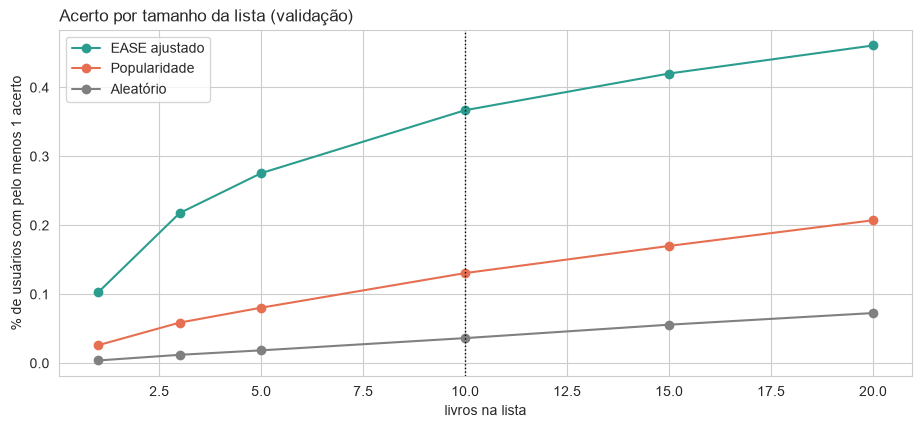

,EASE ajustado,Popularidade,Aleatório,EASE ÷ popularidade
tamanho da lista,,,,
1,0.103,0.026,0.004,3.950
3,0.218,0.059,0.012,3.699
5,0.276,0.080,0.019,3.425
10,0.367,0.131,0.036,2.808
15,0.420,0.170,0.056,2.471
20,0.461,0.207,0.073,2.223


In [37]:
X_t, X_h, X_a = montar_matrizes(no_catalogo, conjunto, itens, filtro_final)
modelos_lista = {'EASE ajustado': EASE(lambda_final).fit(X_t), 'Popularidade': Popularidade().fit(X_t),
                 'Aleatório': Aleatorio().fit(X_t)}
tamanhos = [1, 3, 5, 10, 15, 20]
curva = pd.DataFrame({nome: [avaliar_recomendador(modelo, X_h, X_a, n=n, excluir=bloqueados)[0][f'acerto@{n}'] for n in tamanhos]
                      for nome, modelo in modelos_lista.items()}, index=pd.Index(tamanhos, name='tamanho da lista'))

fig, ax = plt.subplots(figsize=(11, 4.5))
for nome, cor in zip(curva.columns, ['#2a9d8f', '#e76f51', 'grey']):
    ax.plot(curva.index, curva[nome], marker='o', color=cor, label=nome)
ax.axvline(TAMANHO_LISTA, color='black', ls=':', lw=1)
ax.set_xlabel('livros na lista')
ax.set_ylabel('% de usuários com pelo menos 1 acerto')
ax.set_title('Acerto por tamanho da lista (validação)', loc='left')
ax.legend()
salvar_figura('Acerto por tamanho da lista')
plt.show()
curva.assign(**{'EASE ÷ popularidade': curva['EASE ajustado'] / curva['Popularidade']}).round(3)

📌 **Nota: tamanho da lista**
- 🔎 O EASE ganha da popularidade em todos os tamanhos. Com **1 livro**, acerta **10,3%** dos usuários (popularidade **2,6%**); com **10**, **36,7%** (popularidade **13,1%**); com **20**, **46,1%**.
- 🔎 A vantagem relativa é maior nas listas curtas (**3,95 vezes** com 1 livro e **2,8 vezes** com 10), justamente onde o espaço na tela é mais caro.
- ✅ **Decisão:** manter **10 livros**, um tamanho comum numa vitrine. De 10 para 20 livros, o acerto sobe de 36,7% para 46,1%, mas a lista dobra.

## 9 - Teste anti-vazamento

Para mostrar o tamanho do vazamento, treinamos o mesmo EASE **vendo os livros do teste** (eles entram na matriz de treino, mas continuam fora do histórico usado para pontuar). Se o acerto subir muito, a separação está protegendo a avaliação.

In [38]:
X_vazado = matriz_usuario_item(filtro_final(no_catalogo), np.sort(no_catalogo['id_usuario'].unique()), itens)
resumo_vazado, _ = avaliar_recomendador(EASE(lambda_final).fit(X_vazado), X_hist_teste, X_teste, excluir=bloqueados_tv)
pd.DataFrame({'sem vazamento (correto)': resumo_teste, 'modelo viu o teste': resumo_vazado}).drop('popularidade média').round(4)

,sem vazamento (correto),modelo viu o teste
acerto@10,0.4072,0.5816
precisão@10,0.0547,0.0931
recall@10,0.2674,0.4148
ndcg@10,0.1961,0.3080
cobertura,0.8427,0.8551


📌 **Nota: anti-vazamento**
- 🔎 Quando o modelo aprende **vendo os livros do teste**, o acerto@10 salta de **40,7%** para **58,2%** e o recall de **26,7%** para **41,5%**.
- 🔎 Ou seja, sem a separação por usuário, o projeto anunciaria **58,2%** de acerto em vez dos **40,7%** reais.

### 🛡️ Resumo: houve vazamento? Foi resolvido?

| Pergunta | Resposta |
|---|---|
| Houve vazamento? | A v1 não media o acerto, então não havia número para inflar. Na v2, o risco é o modelo ver os livros escondidos, e o teste acima mostra o efeito: **58,2%** em vez de **40,7%** |
| Foi resolvido? | ✅ Sim. Os livros da validação e do teste ficam fora da matriz de treino; o teste foi aberto uma única vez; a nota média do filtro de qualidade vem só do treino |
| E a nota? | A nota só define o acerto (nota ≥ 7); o modelo aprende com quem leu o quê |

# FASE 04: AVALIAÇÃO

## 1 - Avaliando a Máquina Preditiva

In [39]:
avaliados_teste = np.sort(no_catalogo.loc[conjunto == 'teste', 'id_usuario'].unique())
historico = np.asarray(X_hist_teste.getnnz(axis=1))
popular_por_usuario = avaliar_recomendador(Popularidade().fit(X_tv), X_hist_teste, X_teste)[1]
perfil = pd.DataFrame({'livros no histórico': pd.cut(historico, [0, 9, 19, 49, 10_000], labels=['até 9', '10-19', '20-49', '50+']),
                       'EASE': por_usuario_teste['acertos'] > 0, 'Popularidade': popular_por_usuario['acertos'] > 0})
por_perfil = perfil.groupby('livros no histórico', observed=True).agg(usuários=('EASE', 'size'), EASE=('EASE', 'mean'),
                                                                      Popularidade=('Popularidade', 'mean'))
display(por_perfil.round(3))

# Acerto por popularidade do livro escondido: o modelo encontra livros fora dos best-sellers?
listas = modelo_final.recomendar(X_hist_teste, TAMANHO_LISTA, bloqueados_tv)
linhas, colunas = X_teste.nonzero()
encontrado = np.array([coluna in listas[linha] for linha, coluna in zip(linhas, colunas)])
ranking = pd.Series(popularidade).rank(ascending=False).to_numpy()
faixa_popularidade = pd.cut(ranking[colunas], [0, 50, 200, len(itens)], labels=['top 50', '51-200', 'demais'])
pd.DataFrame({'faixa': faixa_popularidade, 'encontrado': encontrado}).groupby('faixa', observed=True)['encontrado'].agg(
    ['size', 'mean']).round(3).rename(columns={'size': 'livros escondidos', 'mean': '% encontrados'})

,usuários,EASE,Popularidade
livros no histórico,,,
até 9,601,0.381,0.053
10-19,689,0.335,0.090
20-49,638,0.436,0.130
50+,383,0.530,0.258


,livros escondidos,% encontrados
faixa,,
top 50,954,0.447
51-200,1620,0.273
demais,2463,0.161


📌 **Nota: acerto por perfil de leitor e por popularidade do livro (teste)**
- 🔎 O EASE ganha da popularidade em todos os perfis. A vantagem é maior para quem tem **até 9 livros** no histórico (**38,1%** × **5,3%**), justamente o leitor que a lista de best-sellers atende pior. Para quem tem 50 ou mais livros, o acerto chega a **53,0%**.
- 🔎 O modelo encontra **44,7%** dos livros escondidos entre os 50 mais lidos, **27,3%** dos livros entre o 51º e o 200º e **16,1%** dos demais. O acerto cai na cauda longa, mas não zera: a lista de populares, por definição, só recomenda o topo.

#### Acerto esperado por número de livros informados

No app, o leitor escolhe só alguns livros de que gostou. Para saber quanto o modelo acerta nessa situação, simulamos no teste: o modelo vê apenas **k livros de que o usuário gostou** (sorteados do histórico) e precisa encontrar os livros escondidos.

In [40]:
_, X_hist_gostou, _ = montar_matrizes(no_catalogo, conjunto, itens, lambda d: filtrar_sinal(d, 'gostou'),
                                      treino=('treino', 'validacao'), alvo='teste')
por_livros = acerto_por_livros_informados(modelo_final, X_hist_gostou, X_teste, excluir=bloqueados_tv)
por_livros['acerto@10 popularidade'] = acerto_por_livros_informados(Popularidade().fit(X_tv), X_hist_gostou, X_teste)['acerto@10']
por_livros.round(3)

,usuários,acerto@10,acerto@10 popularidade
livros informados,,,
1,2311,0.183,0.095
2,2311,0.232,0.096
3,2311,0.276,0.096
5,1846,0.308,0.107
10,646,0.435,0.187


📌 **Nota: acerto esperado por número de livros informados (teste)**

| Livros informados | Usuários | EASE | Popularidade |
|---|---|---|---|
| 1 | 2.311 | **18,3%** | 9,5% |
| 3 | 2.311 | **27,6%** | 9,6% |
| 5 | 1.846 | **30,8%** | 10,7% |
| 10 | 646 | **43,5%** | 18,7% |

- 🔎 Com **um único livro** de que gostou, o leitor já recebe uma lista com pelo menos 1 acerto em **18,3%** dos casos, quase o dobro da vitrine de populares (**9,5%**). Cada livro a mais melhora a lista: com 3 livros, **27,6%**; com 10, **43,5%**.
- 🔎 A popularidade quase não muda até 5 livros, porque a lista dela é a mesma para todos.
- ⚠️ Com 10 livros entram só os **646** usuários que têm tantos livros de que gostaram, leitores mais ativos e mais fáceis de acertar.
- ✅ **Decisão:** o app mostra esse acerto esperado para o número de livros que o leitor escolheu e o que ele ganha escolhendo mais.

## 2 - Previsto x observado

In [41]:
for linha in [0, 1, 2]:
    tem = X_hist_teste[linha].indices
    print(f'Usuário {avaliados_teste[linha]} | {len(tem)} livros no histórico, por exemplo: {"; ".join(nomes[tem[:3]])}')
    display(comparar_lista(modelo_final, X_hist_teste, X_teste, linha, nomes, excluir=bloqueados_tv))

Usuário 243 | 37 livros no histórico, por exemplo: The Lovely Bones: A Novel; A Painted House; Girl with a Pearl Earring


,livro recomendado,gostou (escondido)?
posição,,
1,Violets Are Blue,
2,The Summons,
3,The Da Vinci Code,
4,Digital Fortress : A Thriller,
5,1st to Die: A Novel,
6,The Runaway Jury,
7,The Secret Life of Bees,
8,The Jester,
9,The Notebook,


Usuário 244 | 6 livros no histórico, por exemplo: Life of Pi; Wicked: The Life and Times of the Wicked Witch of the West; Chicken Soup for the Soul (Chicken Soup for the Soul)


,livro recomendado,gostou (escondido)?
posição,,
1,Confessions of an Ugly Stepsister : A Novel,
2,The Da Vinci Code,
3,"Dude, Where's My Country?",
4,Harry Potter and the Chamber of Secrets (Book 2),
5,Little Altars Everywhere: A Novel,
6,The Nanny Diaries: A Novel,
7,Chicken Soup for the Teenage Soul (Chicken Soup for the Soul),
8,The Secret Life of Bees,
9,Girl with a Pearl Earring,


Usuário 254 | 56 livros no histórico, por exemplo: The Secret Life of Bees; Bridget Jones's Diary; Girl with a Pearl Earring


,livro recomendado,gostou (escondido)?
posição,,
1,Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback)),
2,The Lovely Bones: A Novel,
3,Harry Potter and the Sorcerer's Stone (Book 1),✅
4,Brave New World,
5,The Hobbit : The Enchanting Prelude to The Lord of the Rings,
6,The Da Vinci Code,
7,The Bonesetter's Daughter,✅
8,Divine Secrets of the Ya-Ya Sisterhood: A Novel,
9,Watership Down,


In [42]:
# O exemplo da v1: livros parecidos com "Harry Potter and the Chamber of Secrets (Book 2)"
hp2 = int(np.flatnonzero(pd.Series(itens).str.startswith('harry potter and the chamber of secrets'))[0])
X_notas_tudo = matriz_usuario_item(filtrar_sinal(no_catalogo, 'explicitas'), usuarios_catalogo, itens, valor='nota')
euclidiano_tudo = VizinhosItens('euclidiana').fit(X_notas_tudo)
pd.DataFrame({'v1: vizinhos euclidianos': nomes[recomendar_para_leitor(euclidiano_tudo, [hp2], len(itens), 5)],
              'v2: EASE ajustado': nomes[recomendar_para_leitor(modelo_final, [hp2], len(itens), 5, bloqueados_tv)]},
             index=pd.RangeIndex(1, 6, name='posição'))

,v1: vizinhos euclidianos,v2: EASE ajustado
posição,,
1,Harry Potter and the Prisoner of Azkaban (Book 3),Harry Potter and the Prisoner of Azkaban (Book 3)
2,Harry Potter and the Goblet of Fire (Book 4),Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))
3,Harry Potter and the Sorcerer's Stone (Book 1),Harry Potter and the Goblet of Fire (Book 4)
4,Don't Stand Too Close to a Naked Man,Harry Potter and the Sorcerer's Stone (Book 1)
5,"The Reptile Room (A Series of Unfortunate Events, Book 2)",Harry Potter and the Order of the Phoenix (Book 5)


📌 **Nota: exemplos**
- 🔎 O usuário 254 (56 livros no histórico) recebe 2 acertos: *Harry Potter and the Sorcerer's Stone (Book 1)* em 3º e *The Bonesetter's Daughter* em 7º.
- 🔎 Os usuários 243 e 244 não têm acerto, mas as listas fazem sentido. Quem lê John Grisham e James Patterson recebe *The Summons*, *The Runaway Jury*, *The Pelican Brief* e *1st to Die*.
- 🔎 No exemplo da v1 (livros parecidos com *Harry Potter 2*), o EASE devolve só livros da série. A v1 trazia *Don't Stand Too Close to a Naked Man* e *The Reptile Room* em 4º e 5º.

## 3 - Quais variáveis mais influenciam o modelo?

O EASE não usa variáveis dos livros: a pontuação de um livro é a **soma das contribuições dos livros do histórico** (`W[h, j]`). Então cada recomendação se explica pelos livros que o usuário já leu: "recomendado porque você leu X e Y".

In [43]:
linha = 0
tem = X_hist_teste[linha].indices
primeiro = listas[linha][0]
print(f'Usuário {avaliados_teste[linha]} | 1ª recomendação: {nomes[primeiro]}')
display(explicar_recomendacao(modelo_final, tem, primeiro, nomes).head(5).round(3))

# Wild Animus (o mais lido, com notas baixas) aparece nas listas?
listas_popular = Popularidade().fit(X_tv).recomendar(X_hist_teste, TAMANHO_LISTA)
listas_sem_filtro = modelo_final.recomendar(X_hist_teste, TAMANHO_LISTA)
print(f'Listas com Wild Animus: popularidade {np.mean([wild_idx in l for l in listas_popular]):.1%} | '
      f'EASE sem filtro {np.mean([wild_idx in l for l in listas_sem_filtro]):.1%} | '
      f'EASE com filtro {np.mean([wild_idx in l for l in listas]):.1%}')
print(f'Livros diferentes recomendados no teste: EASE {len(np.unique(listas))} | popularidade {len(np.unique(listas_popular))} '
      f'(de {len(itens)})')

Usuário 243 | 1ª recomendação: Violets Are Blue


,contribuição,fração
Roses Are Red (Alex Cross Novels),0.102,0.258
Four Blind Mice,0.055,0.137
2nd Chance,0.048,0.121
All That Remains (Kay Scarpetta Mysteries (Paperback)),0.024,0.060
The Street Lawyer,0.023,0.057


Listas com Wild Animus: popularidade 78.8% | EASE sem filtro 34.1% | EASE com filtro 0.0%


Livros diferentes recomendados no teste: EASE 541 | popularidade 52 (de 642)


📌 **Nota: por que cada livro foi recomendado**
- 🔎 Para o usuário 243, *Violets Are Blue* (série Alex Cross, de James Patterson) vem em 1º sobretudo por *Roses Are Red* (**25,8%** da pontuação), o livro anterior da mesma série, seguido de *Four Blind Mice* (**13,7%**) e *2nd Chance* (**12,1%**), ambos do mesmo autor.
- 🔎 *Wild Animus* aparece em **78,8%** das listas de populares e em **34,1%** das do EASE sem filtro. Com o filtro, aparece em **0%**.
- 🔎 O EASE recomenda **541** livros diferentes no teste; a popularidade, **52** dos 642.
- ✅ **Decisão:** o app mostra esse motivo em cada recomendação ("porque você gostou de X").

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

Depois de medido no teste, o modelo de produção é treinado com **todas** as interações do catálogo (mais leitores = mais co-leituras aprendidas), com o mesmo sinal e o mesmo lambda.

In [44]:
modelo_producao = EASE(lambda_final).fit(X_vazado)
bloqueados_producao = livros_mal_avaliados(no_catalogo, itens)
colunas_catalogo = ['titulo', 'autor', 'ano', 'n_notas', 'nota_media', 'n_leitores', 'capa_m', 'capa_g']
with open(PASTA_MODELO / 'recomendador_livros.pkl', 'wb') as arquivo:
    pickle.dump({'modelo': modelo_producao, 'itens': itens, 'catalogo': catalogo[colunas_catalogo],
                 'excluir': bloqueados_producao, 'acerto_por_livros': por_livros['acerto@10'].round(3).to_dict()}, arquivo)

ficha = salvar_ficha_modelo(
    PASTA_MODELO / 'ficha_modelo.json',
    modelo=f'EASE (regressão item a item com L2), lambda = {lambda_final}',
    sinal_treino=sinal_final,
    nota_gostou=NOTA_GOSTOU,
    catalogo={'obras': len(itens), 'corte_min_notas': MIN_NOTAS_CATALOGO, 'obra': 'título + autor normalizados'},
    interacoes_treino=int(X_vazado.nnz),
    tamanho_lista=TAMANHO_LISTA,
    separacao='60/20/20 por usuário (livros com nota >= 7), usuários com >= 5 livros de que gostaram',
    metricas_teste={k: round(v, 4) for k, v in resumo_teste.items()},
    metricas_teste_popularidade={k: round(v, 4) for k, v in popular_teste.items()},
    acerto_por_livros_informados={int(k): round(v, 3) for k, v in por_livros['acerto@10'].items()},
    filtro_qualidade={'nota_minima': NOTA_MINIMA_RECOMENDAR, 'livros_bloqueados': list(nomes[bloqueados_producao])},
    lista_sem_historico=f'populares_bem_avaliados (nota média >= {NOTA_GOSTOU})',
    avisos=['Recomenda só livros do catálogo (obras com >= 50 notas); livros novos precisam de leitores para entrar.',
            'A base é de 2004 e não tem datas: a separação é aleatória dentro de cada usuário, não no tempo.',
            'Filtragem colaborativa: usa quem leu o quê, não o gênero ou o conteúdo dos livros.'],
)
pd.Series({k: ficha[k] for k in ['modelo', 'sinal_treino', 'interacoes_treino']})

modelo               EASE (regressão item a item com L2), lambda = 200
sinal_treino                                                     todas
interacoes_treino                                               150275
dtype: object

📌 **Nota:** `Model/recomendador_livros.pkl` guarda o modelo (matriz W do EASE, 642 × 642), a ordem dos livros, o catálogo com título, autor e capa e a lista do filtro de qualidade. O modelo de produção aprende com as **150.275** interações. A ficha `Model/ficha_modelo.json` registra o sinal, o lambda, as métricas do teste, o filtro e os avisos.

## 2 - Aplicando uma simulação

In [45]:
with open(PASTA_MODELO / 'recomendador_livros.pkl', 'rb') as arquivo:
    salvo = pickle.load(arquivo)
posicao = pd.Series(np.arange(len(salvo['itens'])), index=salvo['itens'])

# Leitor novo que gostou de 3 livros de suspense
gostou_de = ['the da vinci code | danbrown', 'angels demons | danbrown', 'the bourne identity | robertludlum']
gostou_de = [obra for obra in gostou_de if obra in posicao.index]
escolhidos = posicao[gostou_de].to_numpy()
recomendados = recomendar_para_leitor(salvo['modelo'], escolhidos, len(salvo['itens']), excluir=salvo['excluir'])
simulacao = salvo['catalogo'].iloc[recomendados][['titulo', 'autor', 'nota_media']].reset_index(drop=True)
simulacao.index = pd.RangeIndex(1, len(simulacao) + 1, name='posição')
simulacao['porque você gostou de'] = [explicar_recomendacao(salvo['modelo'], escolhidos, item, salvo['catalogo']['titulo'].to_numpy())
                                     .index[0] for item in recomendados]
print('Gostou de:', '; '.join(salvo['catalogo'].loc[gostou_de, 'titulo']))
display(simulacao.round(2))

# Leitor sem histórico: os mais lidos entre os bem avaliados
populares_bem_avaliados(salvo['catalogo'], n=5)[['titulo', 'autor', 'n_leitores', 'nota_media']].round(2)

Gostou de: The Da Vinci Code; Angels & Demons; The Bourne Identity


,titulo,autor,nota_media,porque você gostou de
posição,,,,
1,Digital Fortress : A Thriller,Dan Brown,7.60,Angels & Demons
2,Deception Point,Dan Brown,7.68,Angels & Demons
3,The Lovely Bones: A Novel,Alice Sebold,8.19,The Da Vinci Code
4,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,9.05,The Da Vinci Code
5,Life of Pi,Yann Martel,8.09,The Da Vinci Code
6,Mystic River,Dennis Lehane,7.93,Angels & Demons
7,The Secret Life of Bees,Sue Monk Kidd,8.48,Angels & Demons
8,"Tuesdays with Morrie: An Old Man, a Young Man, and Life's Greatest...",MITCH ALBOM,8.58,The Bourne Identity
9,Snow Falling on Cedars,David Guterson,7.82,Angels & Demons


,titulo,autor,n_leitores,nota_media
id_obra,,,,
the lovely bones a novel | alicesebold,The Lovely Bones: A Novel,Alice Sebold,1295,8.19
the da vinci code | danbrown,The Da Vinci Code,Dan Brown,897,8.44
divine secrets of the yaya sisterhood a novel | rebeccawells,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,853,7.83
the nanny diaries a novel | emmamclaughlin,The Nanny Diaries: A Novel,Emma McLaughlin,821,7.43
a painted house | johngrisham,A Painted House,John Grisham,818,7.39


📌 **Nota: simulação**
- 🔎 O leitor que gostou de *The Da Vinci Code*, *Angels & Demons* e *The Bourne Identity* recebe primeiro os outros dois livros de Dan Brown no catálogo (*Digital Fortress* e *Deception Point*), ambos "porque você gostou de *Angels & Demons*". Depois vêm livros lidos por quem leu *The Da Vinci Code* (*The Lovely Bones*, *Life of Pi*). *Wild Animus* não aparece.
- 🔎 Quem ainda não escolheu nenhum livro recebe os mais lidos entre os bem avaliados: *The Lovely Bones*, *The Da Vinci Code*, *Divine Secrets of the Ya-Ya Sisterhood*. *Wild Animus* fica fora pela nota.

In [46]:
# Quantos usuários do teste recebem pelo menos 1 livro de que gostaram com X vagas na tela: modelo x sorteio
vagas = [1, 3, 5, 10, 20]
modelos_teste = {'EASE (modelo final)': modelo_final, 'Popularidade': Popularidade().fit(X_tv), 'Sorteio': Aleatorio().fit(X_tv)}
vagas_tabela = pd.DataFrame({nome: [avaliar_recomendador(modelo, X_hist_teste, X_teste, n=n,
                                                         excluir=bloqueados_tv if nome.startswith('EASE') else None)[0][f'acerto@{n}'] * X_teste.shape[0]
                                    for n in vagas] for nome, modelo in modelos_teste.items()},
                            index=pd.Index(vagas, name='vagas na tela')).round(0).astype(int)
print(f'Usuários no teste: {X_teste.shape[0]:,}')
vagas_tabela

Usuários no teste: 2,311


,EASE (modelo final),Popularidade,Sorteio
vagas na tela,,,
1,352,27,7
3,581,124,29
5,723,167,42
10,941,276,91
20,1165,463,171


📌 **Nota: quantos leitores encontram um livro de que gostam, com X vagas na tela (teste, 2.311 usuários)**

| Vagas | EASE | Popularidade | Sorteio |
|---|---|---|---|
| 1 | **352** | 27 | 7 |
| 5 | **723** | 167 | 42 |
| 10 | **941** | 276 | 91 |

- 🔎 Com **uma única vaga**, o modelo acerta para **352** leitores, contra **27** da popularidade. Com 10 vagas, são **941** contra **276**.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

> Dá para recomendar livros de forma personalizada **e medir o acerto**. Com 10 livros por leitor, o modelo final (EASE) coloca pelo menos um livro de que a pessoa gostou na lista de **40,7%** dos leitores do teste, contra **11,9%** de uma vitrine de best-sellers; um sorteio acerta para só **91** dos **2.311** leitores. A configuração da v1 (distância euclidiana) acertava **3,8%** na validação, praticamente o sorteio.

| Pergunta | Resposta | Onde está |
|---|---|---|
| O recomendador acerta? | **40,7%** de acerto@10 no teste (popularidade: **11,9%**) | Fase 03, item 7.3 |
| A v1 funcionava? | Não: o euclidiano da v1 acerta **3,8%**, quase o sorteio (**3,5%**) | Fase 03, item 5 |
| O que mais melhorou o modelo? | Usar as **interações sem nota** que a v1 descartava (de 31,5% para 36,5% na validação) | Fase 03, item 7.1 |
| Por que o modelo recomenda cada livro? | Pelos livros do histórico, ex.: *Violets Are Blue* por *Roses Are Red* (25,8%) | Fase 04, item 3 |
| E o livro muito lido e mal avaliado? | O filtro de qualidade tira *Wild Animus* de **35,8%** das listas, sem perder acerto | Fase 03, item 7.2 |
| A avaliação é confiável? | Separação por usuário, 5 sementes (± 0,8 ponto) e teste aberto uma vez; com vazamento, o acerto subiria para **58,2%** | Fase 03, itens 5, 7 e 9 |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA (teste) | No modelo |
|---|---|---|---|
| H1 | A maioria das interações não tem nota | ✅ 62,3% | As interações sem nota foram o maior ganho do modelo (sinal `todas`) |
| H2 | Mais notas → nota maior | ❌ rho 0,046 | Popularidade não é qualidade: a vitrine de populares acerta só 11,9% |
| H7 | Quem leu HP 1 lê o 2 | ✅ OR 268 | O EASE recomenda só livros da série para *Harry Potter 2*, e a explicação mostra a série (Alex Cross) puxando a recomendação |
| H8 | Muito lido ≠ bem avaliado | ✅ postos −0,743 | Sem o filtro, *Wild Animus* entraria em 35,8% das listas |
| H3–H6 | País, idade, ano, atividade × nota | Efeitos desprezíveis | O modelo não usa essas colunas, e não perde nada por isso |

# 💡 INSIGHTS

1. **Medir antes de afirmar.** O exemplo de Harry Potter da v1 parecia ótimo, mas a média mostra que o método acertava **3,8%**, como o sorteio. Um exemplo bonito não é uma avaliação.
2. **O sinal que parecia lixo era o mais valioso.** As interações sem nota (**62,3%** da base), descartadas na v1 como "notas ruins", elevaram o acerto do EASE de **31,5%** para **36,5%**.
3. **Popularidade não é qualidade.** O livro mais "lido" da base, *Wild Animus*, tem nota 4,4. Um recomendador que conta leitores o empurraria para **35,8%** dos clientes. A regra de negócio (filtro de qualidade) resolve isso sem custo de acerto.
4. **Personalizar vale mais para quem lê pouco.** Com até 9 livros no histórico, o modelo acerta **38,1%** contra **5,3%** da vitrine de best-sellers.
5. **Séries e autores dominam a co-leitura.** Os pares mais parecidos são volumes da mesma série, e as explicações mostram o livro anterior da série como principal motivo. O app deixa isso visível ("porque você gostou de X").
6. **Recomendar a cauda longa.** O modelo usa **541** dos 642 livros nas listas (popularidade: **52**), com livros menos óbvios (popularidade média de **1,2%** × **2,5%**).

### Os limites, ditos com todas as letras

- **Base antiga e sem datas:** os dados são de 2004 e não têm data de leitura. A separação é aleatória dentro de cada usuário, então o modelo foi avaliado em "adivinhar livros escondidos", não em "prever o próximo livro".
- **Catálogo pequeno:** só as **642** obras com 50 notas ou mais. Livros novos ou de nicho precisam de leitores para entrar (o problema de *cold start* do item).
- **Acerto ≠ venda:** o acerto@10 mede se a pessoa gostou de um livro da lista, não se ela compraria. O efeito real exige um teste A/B.
- **Sem conteúdo:** o modelo não sabe o gênero, o resumo ou o autor (exceto pelo que os leitores leem juntos). Um leitor com gosto muito diferente da comunidade recebe recomendações piores.
- **Interações sem nota são ambíguas:** mostram que a pessoa registrou o livro, não que gostou. O filtro de qualidade corrige o caso extremo (*Wild Animus*), mas não todos.

# 🚀 PRÓXIMOS PASSOS

1. **Teste A/B** na vitrine: EASE × best-sellers, medindo cliques e compras.
2. **Separação no tempo**, quando houver datas: treinar no passado e prever as próximas leituras.
3. **Modelo híbrido** para livros novos: usar autor, gênero e descrição (conteúdo) quando o livro ainda não tem leitores suficientes.
4. **Diversidade na lista:** limitar a 2 ou 3 livros da mesma série ou autor por lista, para a vitrine não ficar só com a continuação da série.
5. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que o leitor use o modelo **sem abrir o notebook**, criamos um app em **Streamlit**:
1. O leitor escolhe, na barra lateral, os livros de que gostou (busca pelo título).
2. O app aplica o **modelo salvo** na Fase 05 (com o filtro de qualidade) e mostra **10 recomendações com capa**, cada uma com o motivo ("porque você gostou de X").
3. Mostra o **acerto esperado** para quem informou aquele número de livros (Fase 04, item 1): quanto mais livros, mais certeiras as recomendações.
4. Sem livros escolhidos, mostra os mais lidos entre os bem avaliados.
5. Uma segunda aba mostra os **livros parecidos** com um livro escolhido.

A célula abaixo grava o `app.py` na raiz do projeto. Para executar (na raiz, depois de rodar a Fase 05):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [47]:
%%writefile ../app.py
import pickle
from pathlib import Path

import streamlit as st

from src.dados import populares_bem_avaliados
from src.recomendacao import explicar_recomendacao, recomendar_para_leitor

st.set_page_config(page_title="Recomendação de Livros", page_icon="📚", layout="wide")
st.title("📚 Recomendação de Livros")
st.markdown("Escolha na barra lateral os livros de que você gostou e receba **10 recomendações** a partir do que "
            "leitores com gosto parecido leram e gostaram.")

CAMINHO_MODELO = Path(__file__).parent / "Model" / "recomendador_livros.pkl"


### Carregamento do modelo
@st.cache_resource
def carregar_modelo(caminho):
    with open(caminho, "rb") as arquivo:
        return pickle.load(arquivo)


if not CAMINHO_MODELO.exists():
    st.error("Modelo não encontrado. Execute o notebook até a Fase 05 para gerar a pasta `Model/`.")
    st.stop()

salvo = carregar_modelo(CAMINHO_MODELO)
modelo, itens, catalogo = salvo["modelo"], salvo["itens"], salvo["catalogo"]
excluir = salvo["excluir"]  # filtro de qualidade: livros com nota média abaixo de 5 (ex.: Wild Animus)
acerto_por_livros = salvo["acerto_por_livros"]  # acerto@10 no teste por nº de livros informados (Fase 04)
titulos = catalogo["titulo"].to_numpy()
rotulos = (catalogo["titulo"] + " — " + catalogo["autor"].fillna("?")).to_numpy()


def mostrar_livros(indices, motivos=None):
    """Capas em 5 colunas, com título, autor, nota média, nº de leitores e (opcional) o motivo da recomendação."""
    colunas = st.columns(5)
    for posicao, item in enumerate(indices):
        livro = catalogo.iloc[item]
        with colunas[posicao % 5]:
            if isinstance(livro["capa_m"], str):
                st.image(livro["capa_m"], width=110)
            st.markdown(f"**{posicao + 1}. {livro['titulo']}**  \n{livro['autor']}  \n"
                        f"⭐ {livro['nota_media']:.1f} · {livro['n_leitores']:,} leitores".replace(",", "."))
            if motivos is not None:
                st.caption(motivos[posicao])


### Livros escolhidos pelo leitor
with st.sidebar:
    st.header("📖 Livros de que você gostou")
    escolhidos = st.multiselect("Busque pelo título", options=list(range(len(itens))), format_func=lambda i: rotulos[i],
                                placeholder="Ex.: Harry Potter")
    st.caption(f"Catálogo: {len(itens)} livros com pelo menos 50 notas na base Book-Crossing (2004).")

aba_voce, aba_parecidos = st.tabs(["🎯 Para você", "🔎 Livros parecidos"])

### Recomendações (EASE: cada livro escolhido soma pontos para os livros lidos junto com ele)
with aba_voce:
    if escolhidos:
        recomendados = recomendar_para_leitor(modelo, escolhidos, len(itens), excluir=excluir)
        motivos = []
        for item in recomendados:
            explicacao = explicar_recomendacao(modelo, escolhidos, item, titulos)
            principais = explicacao[explicacao["fração"] > 0].head(2)
            if principais.empty:
                motivos.append("Lido por leitores com gosto parecido com o seu.")
            else:
                motivos.append("Porque você gostou de " + " e ".join(f"*{titulo}* ({fracao:.0%})"
                                                                     for titulo, fracao in principais["fração"].items()))
        st.subheader(f"Recomendações a partir de {len(escolhidos)} livro(s)")
        # Acerto medido no teste para quem informou até esse número de livros (a faixa mais próxima abaixo)
        faixa = max(k for k in acerto_por_livros if k <= len(escolhidos))
        mensagem = (f"📈 Para leitores que informaram {faixa} livro(s), pelo menos 1 destes 10 foi um livro de que "
                    f"gostaram em **{acerto_por_livros[faixa]:.0%}** dos casos (teste).")
        if faixa < max(acerto_por_livros):
            proxima = min(k for k in acerto_por_livros if k > faixa)
            mensagem += f" Com {proxima} livros, sobe para {acerto_por_livros[proxima]:.0%}: escolha mais livros."
        st.info(mensagem)
        mostrar_livros(recomendados, motivos)
        st.caption("A porcentagem é a parte da pontuação do livro que veio de cada livro que você escolheu.")
        with st.expander("📊 Acerto esperado por número de livros informados"):
            st.dataframe({"livros informados": list(acerto_por_livros),
                          "acerto@10 no teste": [f"{v:.0%}" for v in acerto_por_livros.values()]}, hide_index=True)
    else:
        st.subheader("Mais lidos entre os bem avaliados")
        st.caption("Sem livros escolhidos, mostramos os livros com mais leitores entre os de nota média 7 ou mais.")
        populares = populares_bem_avaliados(catalogo, n=10)
        mostrar_livros([catalogo.index.get_loc(obra) for obra in populares.index])

### Livros parecidos com um livro
with aba_parecidos:
    livro = st.selectbox("Escolha um livro", options=list(range(len(itens))), format_func=lambda i: rotulos[i])
    st.subheader(f"Quem gostou de {titulos[livro]} também leu")
    mostrar_livros(recomendar_para_leitor(modelo, [livro], len(itens), excluir=excluir))

Overwriting ../app.py
